In [ ]:
import pandas as pd

## Chargement du DataSet : Youtube Recommendation

In [ ]:
"""
# Chargement du fichier
file_path = "/content/drive/MyDrive/Cours ENET'Com - [2] IDSD /TP ENETCom/TP Data Wrangling/Compte Rendu & Examen/youtube recommendation dataset.csv"
df = pd.read_csv(file_path)
print("Chargement avec succès.")
"""

In [ ]:
file_path =("/Data/youtube recommendation dataset.csv")
df = pd.read_csv(file_path)
print("Chargement avec succès.")

## Exploration des données

In [ ]:
display(df.head())

In [ ]:
# La forme de la Dataset
print("Nombre de lignes : ", df.shape[0])
print("Nombre de colonnes :", df.shape[1])

In [ ]:
# Exploration du type de variable
display(df.info())

*Premiéres conclusions à faire:*
* la colonne **liked** contien des valeurs manquantes
* la colonne **liked** est de forme object pas int
* la colonne **timestamp** est de forme object pas Datetime

In [ ]:
# Statistique descriptive des colonne numérique
display(df.describe())

*Deuxiéme conclusions à faire:*
* la colonne **watch_time** posséde des valeurs négative (des outliers)
* la colonne **watch_percent** à aussi des valeurs négatives
* on peut conclures une relation de coorélation entre ces deux colonnes
* presance de inf et NaN dans mean et std pour la colonne **watch_percent**
* la presance de valeurs null(non numerical) ou manquantes dans la colonne **watch_percent**

In [ ]:
df.columns

In [ ]:
# On s'interesse au colonnes de type "object"
print("Les differents type de like disponible :", df['liked'].unique())
print("\nLes differents type de catégories :", df['category'].unique())
print("\nLes differnets type de devices :", df['device'].unique())
print("\nLes differnets type Watch time of day :",df['watch_time_of_day'].unique())
print("\nLes differnets type timestamp :", df['timestamp'].unique())

*Troisiéme conclusion à faire:*
* **liked** contient des modalités qui ne sont pas cohérantes
* **category** continet des modalités redondantes
* **timestamp** sera développé indépendament

In [101]:
# Description des variables de type "object"
display(
    df.select_dtypes("object").describe()
)

,liked,category,device,watch_time_of_day,timestamp
count,997952,1000000,1000000,1000000,1000000
unique,5,14,4,4,994335
top,0,Comedy,TV,Morning,2025-08-02 23:47:27
freq,696155,124467,250083,250258,3


In [102]:
# compte le nombre d'occurrences de chaque catégorie

print(
    df["category"].value_counts()
)

category
Comedy       124467
News         123920
Music        123851
Tech         123735
Sports       123644
Gaming       123595
Lifestyle    123457
Education    123331
Tech           1749
gamingg        1734
MUsic          1663
Ed             1637
music          1629
COMEDY         1588
Name: count, dtype: int64


* On remarque que les categorie ont présque la proportion (aprés régulation des modalités)

In [103]:
# Recherche de lignes dupliquées
print("Nombre de doublons :", df.duplicated().sum())

Nombre de doublons : 0


In [104]:
# Exploration des lignes avec valeurs nulles
print("Nombre de valeur nulle par colonne : \n", df.isna().sum())
print("\nNombre de valeur nulle total :", df.isna().sum().sum())

Nombre de valeur nulle par colonne : 
 user_id                 0
video_id                0
video_duration          0
watch_time              0
liked                2048
commented               0
subscribed_after        0
category                0
device                  0
watch_time_of_day       0
recommended             0
clicked                 0
timestamp               0
watch_percent           0
dtype: int64

Nombre de valeur nulle total : 2048


* la colonne **liked** est la seule qui continet des valeurs manquantes

In [105]:
# Convertire les date invalide en date valide et la colonne
s = df["timestamp"].astype(str).str.strip()
df["timestamp_dt"] = pd.to_datetime(s, format="%Y-%m-%d %H:%M:%S", errors="coerce")

# check what failed
invalid = df[df["timestamp_dt"].isna()]
print("Nombre de valeurs qui sont pas valides :",len(invalid))
print(invalid["timestamp"].value_counts().head(20))

Nombre de valeurs qui sont pas valides : 2000
timestamp
1744178555    1
1683190037    1
1681563284    1
1708636577    1
1743416259    1
1711575217    1
1725933569    1
1681036320    1
1691520627    1
1677354444    1
1758795352    1
1751749225    1
1727595104    1
1754097569    1
1703188234    1
1680851331    1
1748231626    1
1680961770    1
1717421992    1
1743966085    1
Name: count, dtype: int64


* on a 2000 valeur qui ne verifie pas le type datetime
* on fait la conversion de la colonne **timestamp** en type datetime et on crée une nouvelle colonne timestamp_dt
* les valeurs nulles sont NaT seront converti ensuite

In [106]:
print("le type de la nouvelle colonne timestamp_dt :", df['timestamp_dt'].dtype)

le type de la nouvelle colonne timestamp_dt : datetime64[ns]


In [107]:
# Créer une colonne pour la date et une colonne pour le temps
df["date"] = df["timestamp_dt"].dt.normalize()
df["time"] = df["timestamp_dt"] - df["date"]

print("Type colonne 'date' :", df["date"].dtype)
print("Type colonne 'time' :", df["time"].dtype)

Type colonne 'date' : datetime64[ns]
Type colonne 'time' : timedelta64[ns]


In [108]:
# Nombre de lignes avec NaT dans la colonne 'timestamp_dt'
print("Nombre de ligne avec des valeurs nulles pour 'timestamp_dt' :", (df["timestamp_dt"].isna().sum()))

Nombre de ligne avec des valeurs nulles pour 'timestamp_dt' : 2000


In [109]:
# L'existance de la modalité inf dans 'watch_percent'
somme_inf =(df['watch_percent'] == float('inf')).sum()
print("Le nombre de ligne avec la modalité 'inf': ", somme_inf)

Le nombre de ligne avec la modalité 'inf':  1000


In [110]:
print("Le max dans la variable watch percent: \n",df[df['watch_percent'] > 1]['watch_percent'].unique)

Le max dans la variable watch percent: 
 <bound method Series.unique of 51        3.672523
177            inf
241            inf
242       1.973831
272       1.611558
            ...   
998427    4.357392
998433    7.242847
999320         inf
999494    1.489877
999727    1.433048
Name: watch_percent, Length: 4500, dtype: float64>


* On a 1000 lignes qui présantent la modalité (inf)
* En total on a 4500 lignes qui ont un watch percent > 1

In [111]:
# Existance de video avec 'watch_time' ou 'video_duration' negative
somme_vd_neg = (df['video_duration']<0).sum()
somme_wt_neg = (df['watch_time']<0).sum()
somme_wt_inf = (df['watch_time']==float('inf')).sum()
somme_wt_g_vd = (df['watch_time']>df['video_duration']).sum()
somme_vd_zero = (df['video_duration'] == 0).sum()
print("Nombre de lignes avec watch time négative: ", somme_wt_neg)
print("Nombre de lignes avec video duration négative: ", somme_vd_neg)
print("Nombre de lignes avec watch time > video duration :",somme_wt_g_vd)
print("Nombre de lignes avec watch time de modalité 'inf' :", somme_wt_inf)
print("Nombre de lignes avec video duration ZERO :", somme_vd_zero)

Nombre de lignes avec watch time négative:  500
Nombre de lignes avec video duration négative:  0
Nombre de lignes avec watch time > video duration : 4500
Nombre de lignes avec watch time de modalité 'inf' : 0
Nombre de lignes avec video duration ZERO : 1000


* On a 500 lignes qui on un watch time négative
* On peut voire que le nombre de lignes avec watch percent > 1 est légitime
* On a 1000 ligne qui ont **video_duration** ZERO ce qui explique la présance de 'inf' dans **watch_percent**

In [112]:
df.columns

Index(['user_id', 'video_id', 'video_duration', 'watch_time', 'liked',
       'commented', 'subscribed_after', 'category', 'device',
       'watch_time_of_day', 'recommended', 'clicked', 'timestamp',
       'watch_percent', 'timestamp_dt', 'date', 'time'],
      dtype='object')

*Vérifier les modalités dans les colonnes suivaltes:*
* **commented**
* **subscribed_after**
* **recommanded**
* **clicked**

In [113]:
verif_columns = ['commented', 'subscribed_after', 'recommended', 'clicked']
for col in verif_columns:
  print(f"Les modalité présentent dans la colonne {col} sont: " ,df[col].unique() )

Les modalité présentent dans la colonne commented sont:  [0 1]
Les modalité présentent dans la colonne subscribed_after sont:  [0 1]
Les modalité présentent dans la colonne recommended sont:  [0 1]
Les modalité présentent dans la colonne clicked sont:  [0 1]


* On n'a pas de probléme pour ces variables (peuvent être utiliser comme notre variable de décision)

## Transformation des données

In [114]:
df['liked'] = df['liked'].replace({'yes': '1', 'no': '0'})
display(df['liked'].unique())

array(['1', '0', nan, '2'], dtype=object)

In [115]:
# Calcule le nombre d'obsérvation par modalité pour 'liked'
df['liked'].value_counts(dropna=False)

,count
liked,
0,697143
1,299802
NaN,2048
2,1007


* Étude des données pour faire le changement des modalité 'nan' et '2' dans la colonne **liked**

In [116]:
# Les watch time négative => à 0
df.loc[df["watch_time"] < 0, "watch_time"] = 0
print("Nombre de ligne avec valeur négalive :", (df['watch_time']<0).sum())

Nombre de ligne avec valeur négalive : 0


In [117]:
# Supprimer les lignes avec watch_percent = inf (eq; video_duration = 0)
df = df.drop(df[df['watch_percent'] == float('inf')].index)
print("Nombre de lignes avec modalité 'inf' dans watch percent :",
          (df['watch_percent'] == float('inf')).sum())
print("Watch percent maximal aprés modification :", df['watch_percent'].max())

Nombre de lignes avec modalité 'inf' dans watch percent : 0
Watch percent maximal aprés modification : 225.0606060606061


* Les ligne avec 'inf' sont supprimées
* La présence d'un cas où le watch_percent est trop grand mais pas inf (présence d'outliers)




In [118]:
# Voir les changement dans la variable 'liked' aprés supression de cas
df['liked'].value_counts(dropna=False)

,count
liked,
0,696950
1,299609
NaN,1630
2,811


* Des observation dans la modalité '2' et 'nan' sont supprimer (bonne signe)

In [119]:
# Voir le comportement de l'utilisateur aprés avoir vu une video
# Ce qui nous interesse c'est la modalité 2
Liked_subbed_table = pd.crosstab(
    df["liked"],
    df['subscribed_after'],
    dropna=False

)

display(Liked_subbed_table)

subscribed_after,0,1
liked,,
0,662125,34825
1,284606,15003
2,764,47
NaN,1557,73


* La présance de cas où aprés avoir vu un video l'utilisateur s'est abonné (dans la modalité '2' et 'nan')

In [120]:
# Créer des variables temporelles
df["Year"] = df["date"].dt.year
df["Month"] = df["date"].dt.month
df['Year_Month'] = df['date'].dt.to_period('M')
df["Order_Day"] = df["date"].dt.day
df["dayofweek"] = df["date"].dt.dayofweek
df["Is_Weekend"] = df["date"].dt.dayofweek.isin([5, 6]).astype(int)
df["hour"] = df["timestamp_dt"].dt.hour


In [121]:
# Voir le describsion des heures % au time of day
pd.DataFrame(df.groupby("watch_time_of_day")["hour"].describe())

,count,mean,std,min,25%,50%,75%,max
watch_time_of_day,,,,,,,,
Afternoon,249749.0,11.497552,6.930499,0.0,5.0,11.0,17.0,23.0
Evening,249344.0,11.509160,6.915443,0.0,6.0,12.0,17.0,23.0
Morning,249741.0,11.493523,6.923448,0.0,5.0,11.0,17.0,23.0
Night,249166.0,11.493137,6.919657,0.0,6.0,11.0,17.0,23.0


* tous les time of day sont de 0 à 23
* tous ont la même moyenne et présque la même médiane
* meilleur option est de supprimer ces ligne

In [122]:
df = df.dropna(subset=["timestamp_dt"])
print("Suppression effectué")

Suppression effectué


In [123]:
Liked_subbed_table = pd.crosstab(
    df["liked"],
    df['subscribed_after'],
    dropna=False

)

display(Liked_subbed_table)

subscribed_after,0,1
liked,,
0,661943,34816
1,284403,14996
2,585,37
NaN,1173,47


In [124]:
df['category'].unique()

array(['News', 'Education', 'Sports', 'Gaming', 'Lifestyle', 'Music',
       'Tech', 'Comedy', 'MUsic', 'gamingg', 'music', 'COMEDY', 'Ed',
       'Tech '], dtype=object)

In [125]:
# Réaliser les changements dans la colonne 'category'
Category_valide = [
    "News", "Education", "Sports",
    "Gaming", "Lifestyle", "Music",
    "Tech", "Comedy"
]
correction_Category = {
    "MUsic" : "Music",
    "music" : "Music",
    "gamingg" : "Gaming",
    "COMEDY" : "Comedy",
    "Ed" : "Education",
    "Tech ": "Tech"
}
df['category'] = df['category'].replace(correction_Category)

if(list(df['category'].unique()) == Category_valide):
  print("Changement des doublons avec succés")
else:
  print("echec")


Changement des doublons avec succés


In [126]:
df.columns

Index(['user_id', 'video_id', 'video_duration', 'watch_time', 'liked',
       'commented', 'subscribed_after', 'category', 'device',
       'watch_time_of_day', 'recommended', 'clicked', 'timestamp',
       'watch_percent', 'timestamp_dt', 'date', 'time', 'Year', 'Month',
       'Year_Month', 'Order_Day', 'dayofweek', 'Is_Weekend', 'hour'],
      dtype='object')

In [127]:
# user_id et video_id n'ont aucune importance dans l'entrainement du modèle
# ne présentent aucune information ils sont tous distinct
df = df.drop(['user_id', 'video_id'], axis = 1 )
print("Suppression des colonnes 'user_id' et 'video_id' avec succé")

Suppression des colonnes 'user_id' et 'video_id' avec succé


In [128]:
# Suppression de la colonne 'timestamp'
df = df.drop(['timestamp'], axis =1 )
print("Suppression de la colonne 'timestamp' avec succé")

Suppression de la colonne 'timestamp' avec succé


## Check point de ce que nous avons fait:
*Travail Exécuté:*
* Exploration des données
* transformer la colonne **timestamp** en **timestamp_dt** de type datetime
* créer les colonnes date/ time/ variables temporelles
* transformer les valeur **watch_time** < 0 en 0
* supprimer les lignes avec **video_duration** = 0
* supprimer les lignes avec **timestamp_dt** nulles
* gérer les doublons dans la colonne **category**
* supprimer les colonnes **user_id, video_id, timestamp**

*Travail À Faire:*
* Visualization des données
* Interpréter des relation pour faire les changements nécessaires
* Gérer les valeurs dans **liked**


## Visualization et Interprétation de la variable **liked**

In [129]:
from numpy import nan
import matplotlib.pyplot as plt
import seaborn as sns


# Create a copy of df and handle NaN representation for easy grouping and plotting
df_viz = df.copy()
df_viz["liked"] = df_viz["liked"].fillna("NaN")        # assign back to the column
df_target = df_viz[df_viz["liked"].astype(str).isin(["2", "NaN"])]
display(df_target.head())

,video_duration,watch_time,liked,commented,subscribed_after,category,device,watch_time_of_day,recommended,clicked,...,timestamp_dt,date,time,Year,Month,Year_Month,Order_Day,dayofweek,Is_Weekend,hour
242,2331,4601.0,NaN,0,0,Gaming,Desktop,Evening,1,0,...,2024-01-11 13:39:11,2024-01-11,0 days 13:39:11,2024.0,1.0,2024-01,11.0,3.0,0,13.0
272,2734,4406.0,NaN,0,0,Music,TV,Morning,0,0,...,2025-09-14 23:01:42,2025-09-14,0 days 23:01:42,2025.0,9.0,2025-09,14.0,6.0,1,23.0
362,191,9433.0,NaN,0,0,Music,Mobile,Evening,1,0,...,2023-07-27 16:28:49,2023-07-27,0 days 16:28:49,2023.0,7.0,2023-07,27.0,3.0,0,16.0
1168,2631,2776.0,NaN,0,0,Music,Desktop,Night,1,0,...,2023-10-05 13:18:27,2023-10-05,0 days 13:18:27,2023.0,10.0,2023-10,5.0,3.0,0,13.0
1876,3445,7420.0,2,0,1,Comedy,Tablet,Morning,0,0,...,2025-01-07 11:41:10,2025-01-07,0 days 11:41:10,2025.0,1.0,2025-01,7.0,1.0,0,11.0


In [130]:
print("Taill de la DataFrame target :", df_target.shape)

Taill de la DataFrame target : (1842, 21)


In [131]:
print(df_target['liked'].value_counts(dropna=False))

liked
NaN    1220
2       622
Name: count, dtype: int64


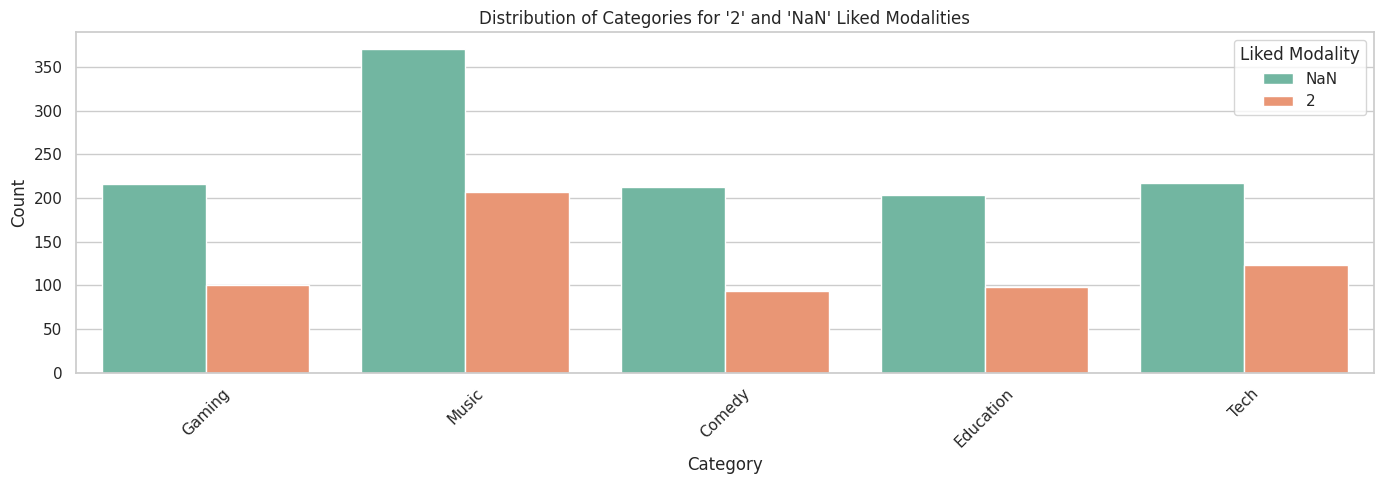

In [132]:
# Set the visualization style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (15, 12)

# 1. Bar Plot: Category Distribution for '2' and 'NaN' modalities
plt.figure(figsize=(14, 5))
sns.countplot(data=df_target, x='category', hue='liked', palette='Set2')
plt.title("Distribution of Categories for '2' and 'NaN' Liked Modalities")
plt.xlabel("Category")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.legend(title="Liked Modality")
plt.tight_layout()
plt.show()


* vérifier si les modalitées ont une relation seulement avec une de ces catégories

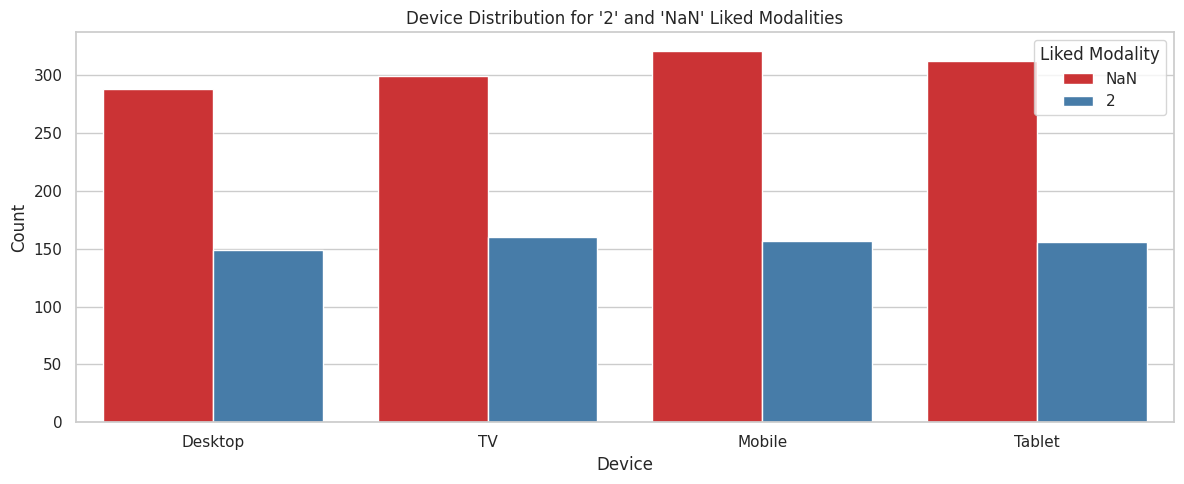

In [133]:
# 2. Bar Plot: Device Distribution
plt.figure(figsize=(12, 5))
sns.countplot(data=df_target, x='device', hue='liked', palette='Set1')
plt.title("Device Distribution for '2' and 'NaN' Liked Modalities")
plt.xlabel("Device")
plt.ylabel("Count")
plt.legend(title="Liked Modality")
plt.tight_layout()
plt.show()


* pas de différence entre la répartion donc c'est pas un critére de choix

In [134]:
df.shape

(998000, 21)

In [135]:
# 3. Pivot Tables & Cross-tabulations avec variables de décision binaire
print("=== Cross-tabulation: Liked ('2'/'NaN') vs. Commented ===")
display(pd.crosstab(df['liked'], df['commented'], dropna=False))

=== Cross-tabulation: Liked ('2'/'NaN') vs. Commented ===


commented,0,1
liked,,
0,627657,69102
1,269403,29996
2,547,75
NaN,1091,129


In [136]:
print("\n=== Cross-tabulation: Liked ('2'/'NaN') vs. Clicked ===")
display(pd.crosstab(df['liked'], df['clicked'], dropna=False))


=== Cross-tabulation: Liked ('2'/'NaN') vs. Clicked ===


clicked,0,1
liked,,
0,487138,209621
1,209378,90021
2,438,184
NaN,857,363


In [137]:
print("\n=== Pivot Table: Mean watch_percent and watch_time by Liked Modality and Category ===")
pivot_metrics = df.pivot_table(
    index='category',
    columns='liked',
    values=['watch_percent', 'watch_time', 'video_duration'],
    aggfunc='mean',
    dropna=False

)
display(pivot_metrics.round(2))


=== Pivot Table: Mean watch_percent and watch_time by Liked Modality and Category ===


video_duration                            watch_percent              \
liked                  0        1        2      NaN             0     1     2   
category                                                                        
Comedy           1814.17  1815.68  1990.55  1919.00          0.75  0.76  6.29   
Education        1817.62  1817.15  1898.24  1814.60          0.75  0.77  6.39   
Gaming           1818.38  1804.04  1837.75  1810.24          0.76  0.76  5.35   
Lifestyle        1814.07  1821.11      NaN      NaN          0.75  0.75   NaN   
Music            1814.64  1812.40  1797.28  1735.01          0.76  0.79  7.95   
News             1813.87  1807.09      NaN      NaN          0.75  0.75   NaN   
Sports           1811.50  1817.15      NaN      NaN          0.75  0.75   NaN   
Tech             1821.85  1816.65  1919.79  1704.34          0.76  0.76  5.14   

                watch_time                             
liked       NaN          0        1        2      NaN  
category                                               
Comedy     6.58    1217.06  1227.23  7097.48  7071.57  
Education  8.04    1218.43  1236.10  6753.97  6897.21  
Gaming     8.04    1219.29  1216.96  6873.20  6876.27  
Lifestyle   NaN    1213.99  1212.60      NaN      NaN  
Music      9.23    1224.20  1239.09  7025.91  6694.34  
News        NaN    1209.75  1202.36      NaN      NaN  
Sports      NaN    1209.13  1213.55      NaN      NaN  
Tech       8.98    1222.65  1224.11  6830.89  6676.29

/tmp/ipykernel_1824/415351810.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_target, x='liked', y='watch_percent', palette='Pastel1')


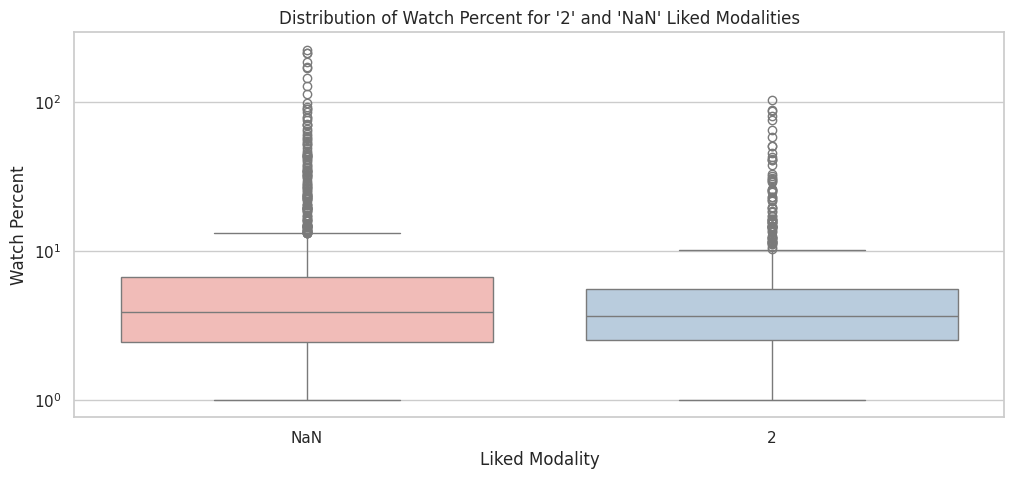

In [138]:
# 4. Box Plot: Distribution of watch_percent
plt.figure(figsize=(12, 5))
sns.boxplot(data=df_target, x='liked', y='watch_percent', palette='Pastel1')
plt.title("Distribution of Watch Percent for '2' and 'NaN' Liked Modalities")
plt.xlabel("Liked Modality")
plt.ylabel("Watch Percent")
plt.yscale('log')
plt.show()

* présence de outliers mais qui peuvent être des informations utiles
* la condition si 10 < watch_percent < 50 on affecte a liked = 1
* la condition si watch_percent >= 50 on affecte liked = 0 (on affecte liked =1 si la categorie est Music)

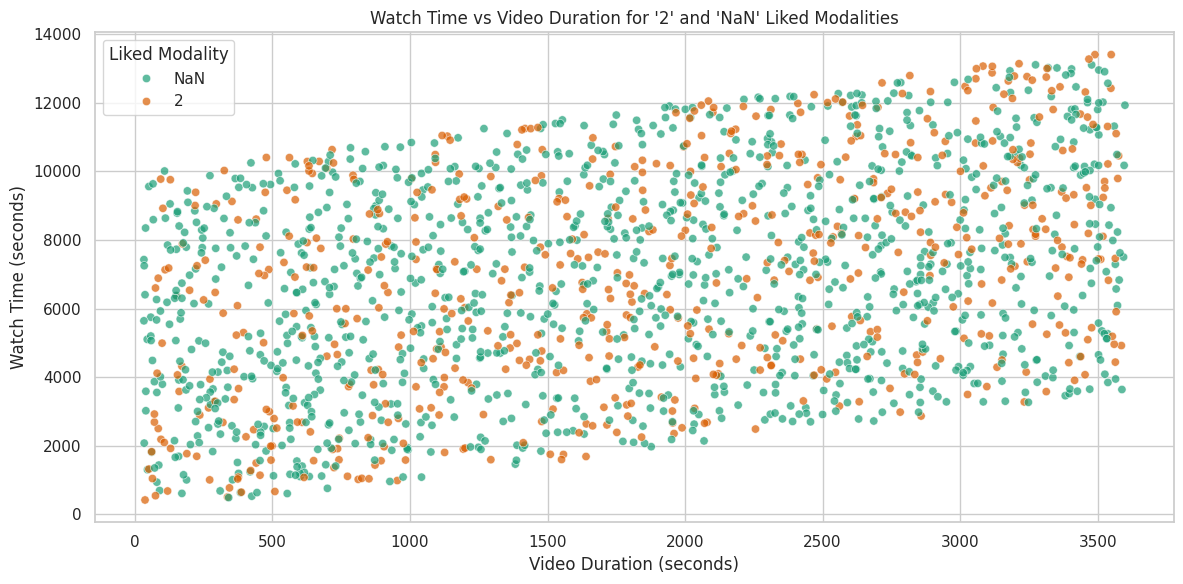

In [139]:
# 5. Scatter Plot: watch_time vs video_duration colored by Liked Modalities
plt.figure(figsize=(12, 6))
sns.scatterplot(
    data=df_target,
    x='video_duration',
    y='watch_time',
    hue='liked',
    alpha=0.7,
    palette='Dark2'
)
plt.title("Watch Time vs Video Duration for '2' and 'NaN' Liked Modalities")
plt.xlabel("Video Duration (seconds)")
plt.ylabel("Watch Time (seconds)")
plt.legend(title="Liked Modality")
plt.tight_layout()
plt.show()

In [140]:
# Prepare target DataFrame with indicator variables for '2' and 'NaN'
df_target = df_target.copy()
df_target['liked'] = df_target['liked'].replace({'2': 1, 'NaN' : 0})

# Select numeric columns available in df_target
numeric_cols = df_target.select_dtypes(include=['int64', 'float64']).columns
print('Colonnes numériques : ', numeric_cols)


Colonnes numériques :  Index(['video_duration', 'watch_time', 'liked', 'commented',
       'subscribed_after', 'recommended', 'clicked', 'watch_percent', 'Year',
       'Month', 'Order_Day', 'dayofweek', 'Is_Weekend', 'hour'],
      dtype='object')


/tmp/ipykernel_1824/1580981986.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_target['liked'] = df_target['liked'].replace({'2': 1, 'NaN' : 0})


In [141]:
# Calculer la matrice de  correlation
corr_matrix = df_target[numeric_cols].corr()

In [142]:
# 1. trie correlations decroissant
print("=== Correlation de touts les  variables avec Liked ===")
corr_trie = corr_matrix['liked'].drop(['liked']).sort_values(ascending=False)
display(corr_trie)

=== Correlation de touts les  variables avec Liked ===


,liked
subscribed_after,0.047516
video_duration,0.038678
recommended,0.025580
commented,0.022365
watch_time,0.016561
Month,0.014227
Order_Day,0.009131
hour,0.006842
clicked,-0.001781
Year,-0.003002


* Notre décision sera fortement liée a **video_duration** et **recommeded** pour le choix des valeurs affecter a liked

In [143]:
# 3. Time Series Evolution: calculer la moyenne de watch_percent et watch_time
# On s'assure de recréer df_target proprement à partir du dataframe principal 'df'
df_target_clean = df[df['liked'].fillna('NaN').astype(str).isin(['2', 'NaN'])].copy()
df_target_clean['liked'] = df_target_clean['liked'].fillna('NaN').astype(str)

# Calcul de l'évolution temporelle
time_evolution = df_target_clean.groupby(['Year_Month', 'liked'])[['watch_percent', 'watch_time']].mean().reset_index()
time_evolution['Year_Month'] = time_evolution['Year_Month'].astype(str)

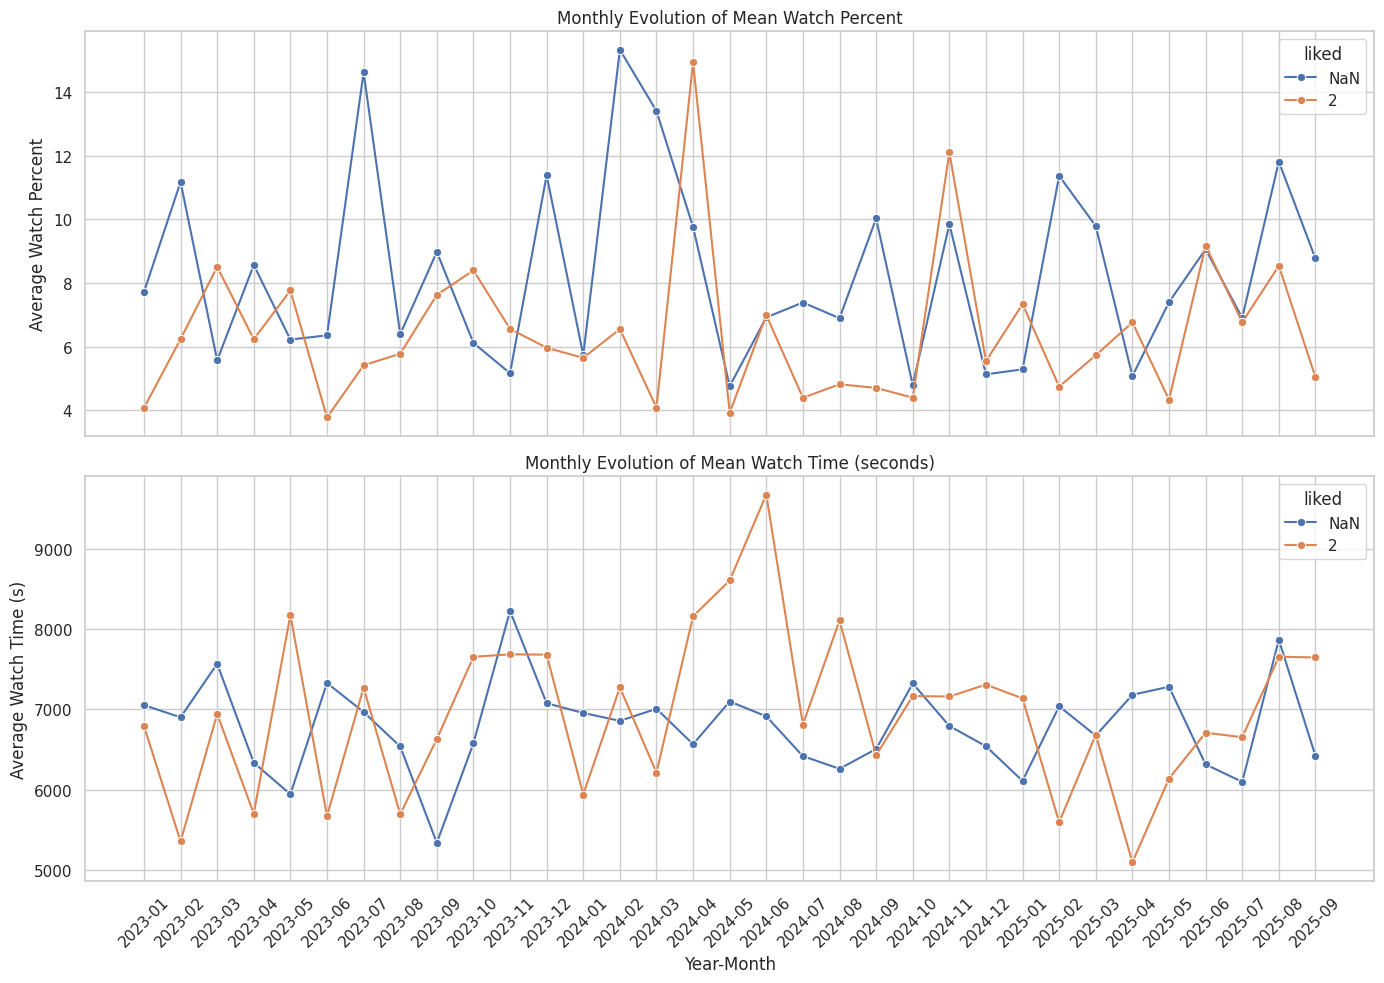

In [144]:


# Plot the evolution
fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

sns.lineplot(data=time_evolution, x='Year_Month', y='watch_percent', hue='liked', marker='o',hue_order=['NaN', '2'], ax=axes[0])
axes[0].set_title("Monthly Evolution of Mean Watch Percent")
axes[0].set_ylabel("Average Watch Percent")

sns.lineplot(data=time_evolution, x='Year_Month', y='watch_time', hue='liked', marker='o',hue_order=['NaN', '2'], ax=axes[1])
axes[1].set_title("Monthly Evolution of Mean Watch Time (seconds)")
axes[1].set_ylabel("Average Watch Time (s)")
axes[1].set_xlabel("Year-Month")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

* On peut se dire que si les deux modalitées présentent un pick a la même période et présentent le même genres alors il auront la même valeur de modalité (0 ou 1)
* si ils ne présentent pas le même pick, ils ont des modalitées différentes

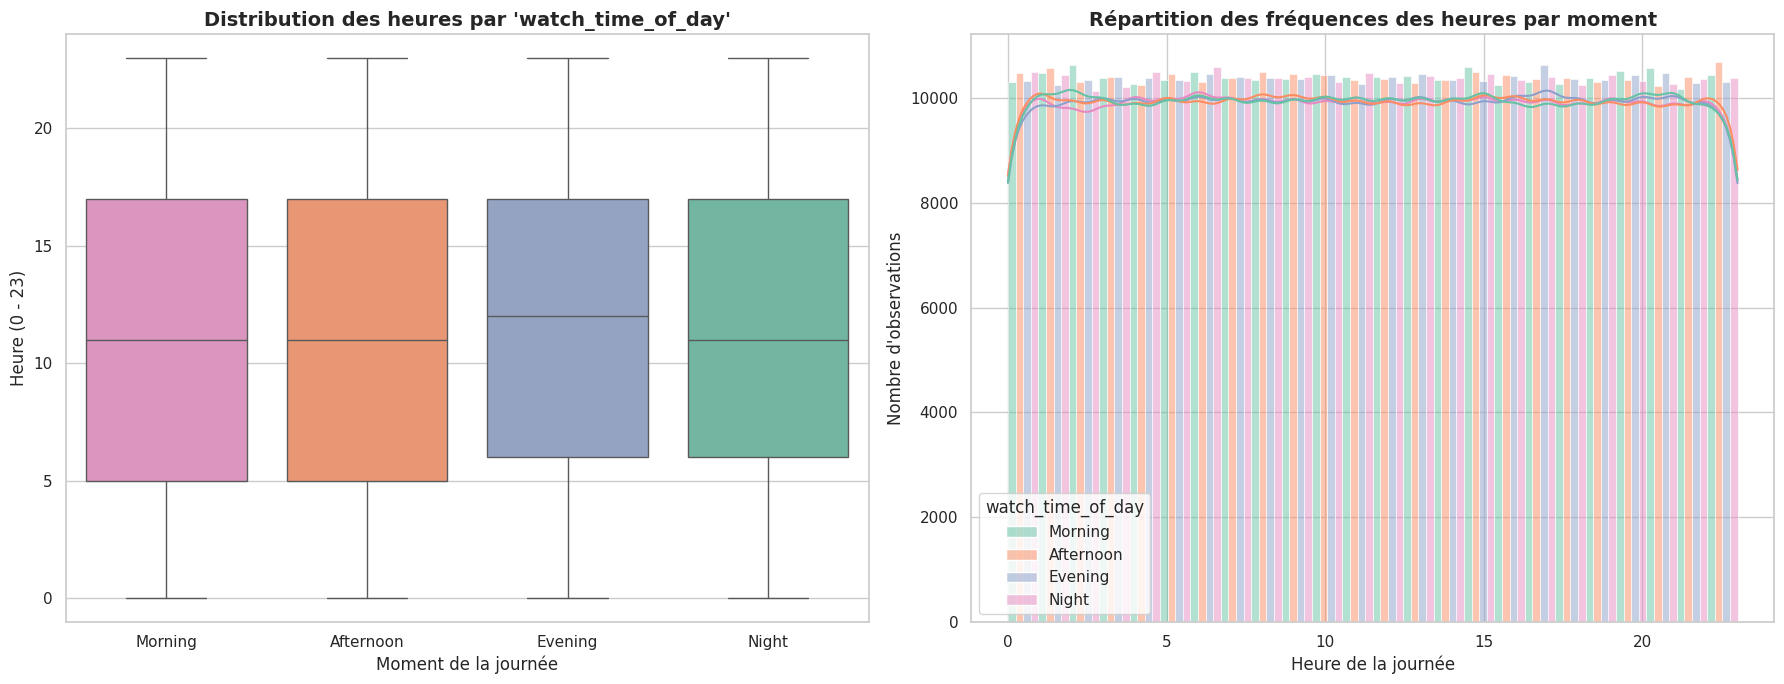

In [145]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration du style des graphiques
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Ordre logique pour l'affichage des moments de la journée
ordre_moments = ['Morning', 'Afternoon', 'Evening', 'Night']

# 1. Boxplot de l'heure par rapport au moment de la journée
sns.boxplot(
    data=df,
    x='watch_time_of_day',
    y='hour',
    order=ordre_moments,
    palette='Set2',
    hue='watch_time_of_day',
    legend=False,
    ax=axes[0]
)
axes[0].set_title("Distribution des heures par 'watch_time_of_day'", fontsize=14, fontweight='bold')
axes[0].set_xlabel("Moment de la journée", fontsize=12)
axes[0].set_ylabel("Heure (0 - 23)", fontsize=12)
axes[0].set_ylim(-1, 24)

# 2. Histogramme / KDE superposé pour voir la distribution des heures
sns.histplot(
    data=df,
    x='hour',
    hue='watch_time_of_day',
    hue_order=ordre_moments,
    kde=True,
    multiple='dodge',
    bins=24,
    palette='Set2',
    ax=axes[1]
)
axes[1].set_title("Répartition des fréquences des heures par moment", fontsize=14, fontweight='bold')
axes[1].set_xlabel("Heure de la journée", fontsize=12)
axes[1].set_ylabel("Nombre d'observations", fontsize=12)

plt.tight_layout()
plt.show()

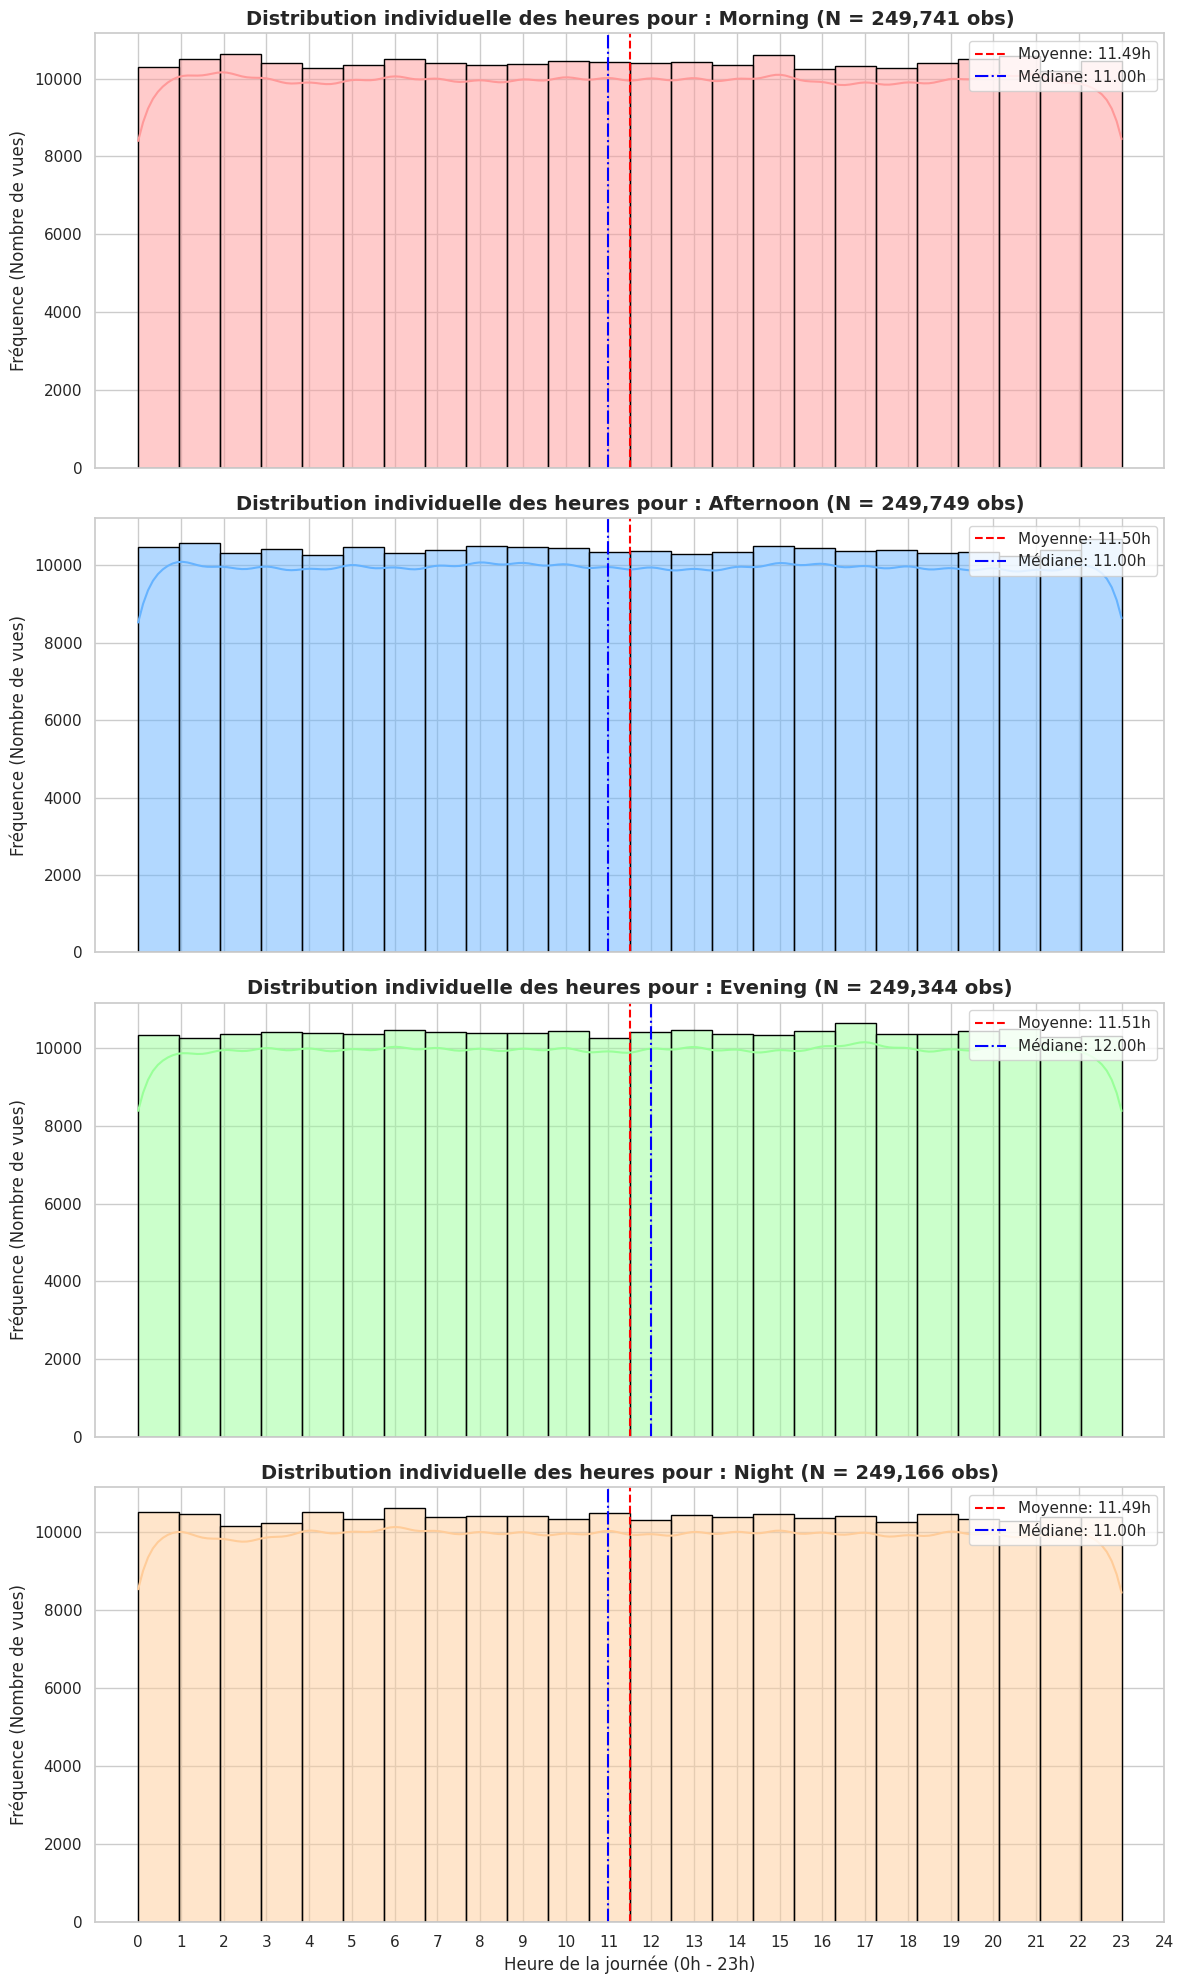

In [146]:
# Liste des modalités individuelles de watch_time_of_day
moments = ['Morning', 'Afternoon', 'Evening', 'Night']

# Configuration de la figure avec 4 sous-graphiques individuels
fig, axes = plt.subplots(4, 1, figsize=(12, 20), sharex=True)

# Palette de couleurs distinctes pour chaque modalité
couleurs = ['#ff9999', '#66b3ff', '#99ff99', '#ffcc99']

for i, moment in enumerate(moments):
    # Filtrer les données pour la modalité spécifique
    df_moment = df[df['watch_time_of_day'] == moment]

    # Histogramme de la distribution des heures pour ce moment précis
    sns.histplot(
        data=df_moment,
        x='hour',
        bins=24,
        kde=True,
        color=couleurs[i],
        ax=axes[i],
        edgecolor='black'
    )

    # Statistiques clés pour affichage sur le graphique
    mean_hour = df_moment['hour'].mean()
    median_hour = df_moment['hour'].median()
    count_obs = len(df_moment)

    # Ajout de lignes verticales indicatrices
    axes[i].axvline(mean_hour, color='red', linestyle='--', linewidth=1.5, label=f'Moyenne: {mean_hour:.2f}h')
    axes[i].axvline(median_hour, color='blue', linestyle='-.', linewidth=1.5, label=f'Médiane: {median_hour:.2f}h')

    # Configuration des titres et labels
    axes[i].set_title(f"Distribution individuelle des heures pour : {moment} (N = {count_obs:,} obs)", fontsize=14, fontweight='bold')
    axes[i].set_ylabel("Fréquence (Nombre de vues)", fontsize=12)
    axes[i].legend(loc='upper right')
    axes[i].set_xlim(-1, 24)
    axes[i].set_xticks(range(25))

# Label de l'axe X pour le dernier graphique
axes[-1].set_xlabel("Heure de la journée (0h - 23h)", fontsize=12)

plt.tight_layout()
plt.show()

* pas de relation entre le **watch_time_of_day** et **hour**
* la distribution de **watch_time_of_day** est uniforme
* on supprime la colonne **watch_time_of_day**

In [147]:
df = df.drop(['watch_time_of_day'], axis=1)
print("Colonne 'watch_time_of_day' supprimée")

Colonne 'watch_time_of_day' supprimée


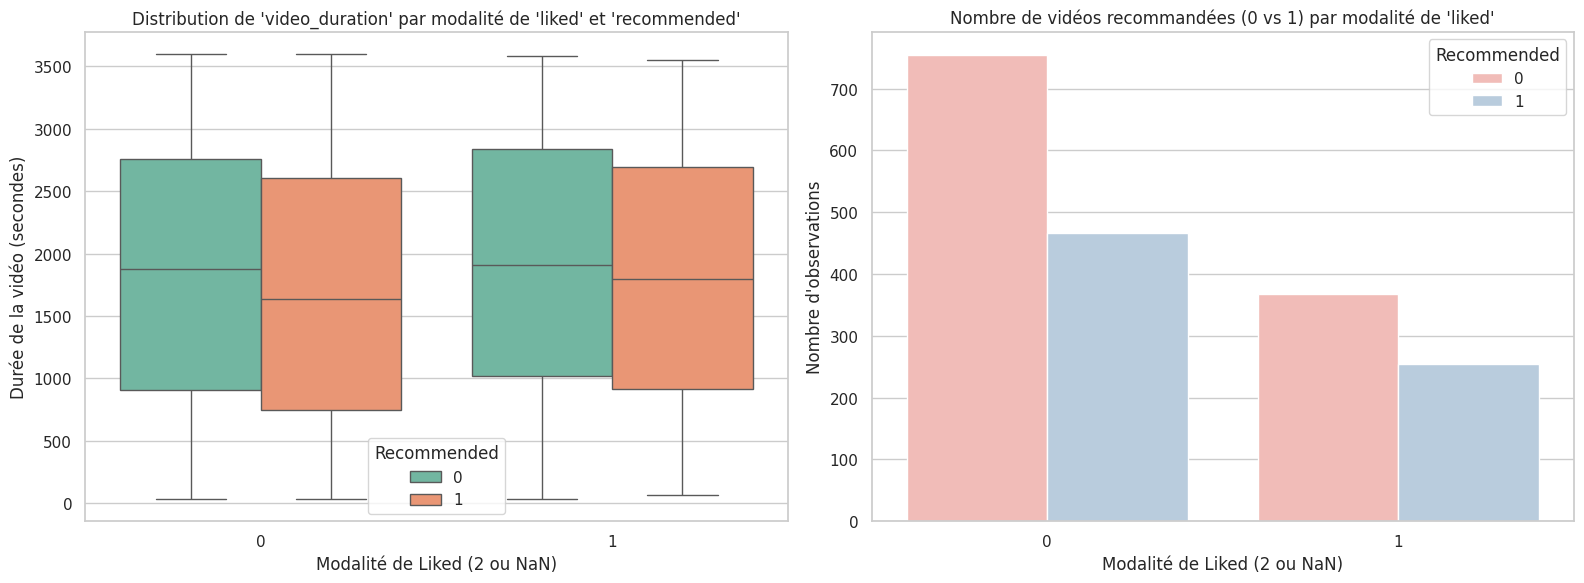

Visualisation complétée avec succès dans la cellule précédente.


In [148]:
# 1. S'assurer que recommended soit traité comme une catégorie (binaire sous forme de chaîne)
df_target_clean['recommended'] = df_target_clean['recommended'].astype(str)

# 2. Création des deux graphiques côte à côte pour l'analyse
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Graphique 1 : Boxplot de video_duration selon liked et recommended
sns.boxplot(
    data=df_target,
    x='liked',
    y='video_duration',
    hue='recommended',
    palette='Set2',
    ax=axes[0]
)
axes[0].set_title("Distribution de 'video_duration' par modalité de 'liked' et 'recommended'")
axes[0].set_xlabel("Modalité de Liked (2 ou NaN)")
axes[0].set_ylabel("Durée de la vidéo (secondes)")
axes[0].legend(title="Recommended")

# Graphique 2 : Countplot de recommended selon liked
sns.countplot(
    data=df_target,
    x='liked',
    hue='recommended',
    palette='Pastel1',
    ax=axes[1]
)
axes[1].set_title("Nombre de vidéos recommandées (0 vs 1) par modalité de 'liked'")
axes[1].set_xlabel("Modalité de Liked (2 ou NaN)")
axes[1].set_ylabel("Nombre d'observations")
axes[1].legend(title="Recommended")

plt.tight_layout()
plt.show()

print("Visualisation complétée avec succès dans la cellule précédente.")

In [149]:
# Tableau croisé simple (effectifs)
ct_raw = pd.crosstab(df['liked'], df['recommended'], dropna=False)
print("=== Tableau croisé (Effectifs bruts) ===")
display(ct_raw)

# Tableau croisé avec pourcentages (normalisé par ligne)
ct_percent = pd.crosstab(df['liked'], df['recommended'], normalize='index', dropna=False) * 100
print("\n=== Tableau croisé (Pourcentages par ligne / %) ===")
display(ct_percent.round(2))

=== Tableau croisé (Effectifs bruts) ===


recommended,0,1
liked,,
0,418071,278688
1,179856,119543
2,368,254
NaN,754,466



=== Tableau croisé (Pourcentages par ligne / %) ===


recommended,0,1
liked,,
0,60.00,40.00
1,60.07,39.93
2,59.16,40.84
NaN,61.80,38.20


*  La durée du vidéo n'a pas réellement d'impacte sur si il est recommender ou non
* les proportion sont préseque equivalantes pas de conclusion

## Changement des modalitées par filtrages

In [150]:
# Suppression des lignes avec watch_percent > 100 (outliers)
print("Nombre de lignes avant filtrage :", df.shape[0])
df = df[df['watch_percent'] <= 40]
print("Nombre de lignes après suppression des watch_percent > 100 :", df.shape[0])

Nombre de lignes avant filtrage : 998000
Nombre de lignes après suppression des watch_percent > 100 : 997913


In [151]:
def get_liked(row):
    like = str(row["liked"])
    wp = row["watch_percent"]

    if like in ["0", "1"]:
        return int(like)
    elif like in ["2", "nan"]:
        if row["recommended"] == 1 and str(row["category"]).lower() == "music" and wp > 20:
            return 1
        elif wp >= 1 and row["commented"] == 1:
            return 1
        elif wp < 0.5:
            return 0
        else:
            return None
    return None



In [152]:
df["liked"] = df.apply(get_liked, axis=1)

In [153]:
df = df.dropna(subset=["liked"])
df["liked"] = df["liked"].astype(int)
print("Les modalité présente aprés filtrage: ", df['liked'].unique(),
      "\nde type :", df['liked'].dtype)

Les modalité présente aprés filtrage:  [1 0] 
de type : int64


In [154]:
# Longeur du Dataset aprés changement
print("Taille :", len(df))
print(df["liked"].value_counts())

Taille : 996336
liked
0    696743
1    299593
Name: count, dtype: int64


In [155]:
df_copy = df.drop('liked', axis =1).copy()
df_target_copy = df_target_clean.drop('liked', axis=1).copy()

In [156]:
common = df_target_copy.index.intersection(df_copy.index)

changed = df.loc[common].copy()
changed["liked_old"] = df_target_clean.loc[common, "liked"]
changed["liked_new"] = df.loc[common, "liked"]

In [157]:
display(changed.head())
print("Taille des lignes changées :", changed.shape[0])

,video_duration,watch_time,liked,commented,subscribed_after,category,device,recommended,clicked,watch_percent,...,time,Year,Month,Year_Month,Order_Day,dayofweek,Is_Weekend,hour,liked_old,liked_new
3349,1815,6662.0,1,1,0,Comedy,Mobile,0,0,3.670523,...,0 days 15:29:20,2023.0,4.0,2023-04,9.0,6.0,1,15.0,2,1
7808,1402,8117.0,1,1,0,Music,Tablet,0,0,5.789586,...,0 days 18:13:38,2023.0,2.0,2023-02,16.0,3.0,0,18.0,NaN,1
14011,3491,9187.0,1,1,0,Tech,Mobile,1,0,2.631624,...,0 days 13:17:57,2025.0,7.0,2025-07,2.0,2.0,0,13.0,NaN,1
18066,455,1135.0,1,1,0,Gaming,Mobile,1,1,2.494505,...,0 days 11:31:59,2025.0,4.0,2025-04,13.0,6.0,1,11.0,2,1
23870,1975,5725.0,1,1,0,Music,Mobile,1,1,2.898734,...,0 days 16:16:52,2025.0,5.0,2025-05,12.0,0.0,0,16.0,2,1


Taille des lignes changées : 209


In [158]:
deleted = df_target_clean.loc[df_target_clean.index.difference(df_copy.index)]

In [159]:
display(deleted.head())
print("Taille des lignes supprimées :", deleted.shape[0])

,video_duration,watch_time,liked,commented,subscribed_after,category,device,watch_time_of_day,recommended,clicked,...,timestamp_dt,date,time,Year,Month,Year_Month,Order_Day,dayofweek,Is_Weekend,hour
242,2331,4601.0,NaN,0,0,Gaming,Desktop,Evening,1,0,...,2024-01-11 13:39:11,2024-01-11,0 days 13:39:11,2024.0,1.0,2024-01,11.0,3.0,0,13.0
272,2734,4406.0,NaN,0,0,Music,TV,Morning,0,0,...,2025-09-14 23:01:42,2025-09-14,0 days 23:01:42,2025.0,9.0,2025-09,14.0,6.0,1,23.0
362,191,9433.0,NaN,0,0,Music,Mobile,Evening,1,0,...,2023-07-27 16:28:49,2023-07-27,0 days 16:28:49,2023.0,7.0,2023-07,27.0,3.0,0,16.0
1168,2631,2776.0,NaN,0,0,Music,Desktop,Night,1,0,...,2023-10-05 13:18:27,2023-10-05,0 days 13:18:27,2023.0,10.0,2023-10,5.0,3.0,0,13.0
1876,3445,7420.0,2,0,1,Comedy,Tablet,Morning,0,0,...,2025-01-07 11:41:10,2025-01-07,0 days 11:41:10,2025.0,1.0,2025-01,7.0,1.0,0,11.0


Taille des lignes supprimées : 1633


## Exploration Analytique (EDA)

In [160]:
df.head()

,video_duration,watch_time,liked,commented,subscribed_after,category,device,recommended,clicked,watch_percent,timestamp_dt,date,time,Year,Month,Year_Month,Order_Day,dayofweek,Is_Weekend,hour
0,1499,1499.0,1,0,0,News,TV,0,0,1.000000,2025-07-16 06:10:54,2025-07-16,0 days 06:10:54,2025.0,7.0,2025-07,16.0,2.0,0,6.0
1,2955,2955.0,1,0,0,Education,Mobile,1,1,1.000000,2024-07-09 10:22:22,2024-07-09,0 days 10:22:22,2024.0,7.0,2024-07,9.0,1.0,0,10.0
2,389,389.0,0,0,0,Sports,Desktop,0,0,1.000000,2025-02-07 09:46:36,2025-02-07,0 days 09:46:36,2025.0,2.0,2025-02,7.0,4.0,0,9.0
3,1231,1231.0,1,1,0,Gaming,TV,0,0,1.000000,2024-04-28 08:07:13,2024-04-28,0 days 08:07:13,2024.0,4.0,2024-04,28.0,6.0,1,8.0
4,3573,353.0,0,1,0,Lifestyle,Desktop,1,0,0.098797,2024-03-30 12:54:24,2024-03-30,0 days 12:54:24,2024.0,3.0,2024-03,30.0,5.0,1,12.0


In [161]:
df.dtypes

,0
video_duration,int64
watch_time,float64
liked,int64
commented,int64
subscribed_after,int64
category,object
device,object
recommended,int64
clicked,int64
watch_percent,float64


*Analyse de la variable cible (subscribed_after)*

Distribution de la variable cible 'subscribed_after':

Nombre de clients non abonné (0): 946518 (95.00%)
Nombre de clients abonné (1): 49818 (5.00%)


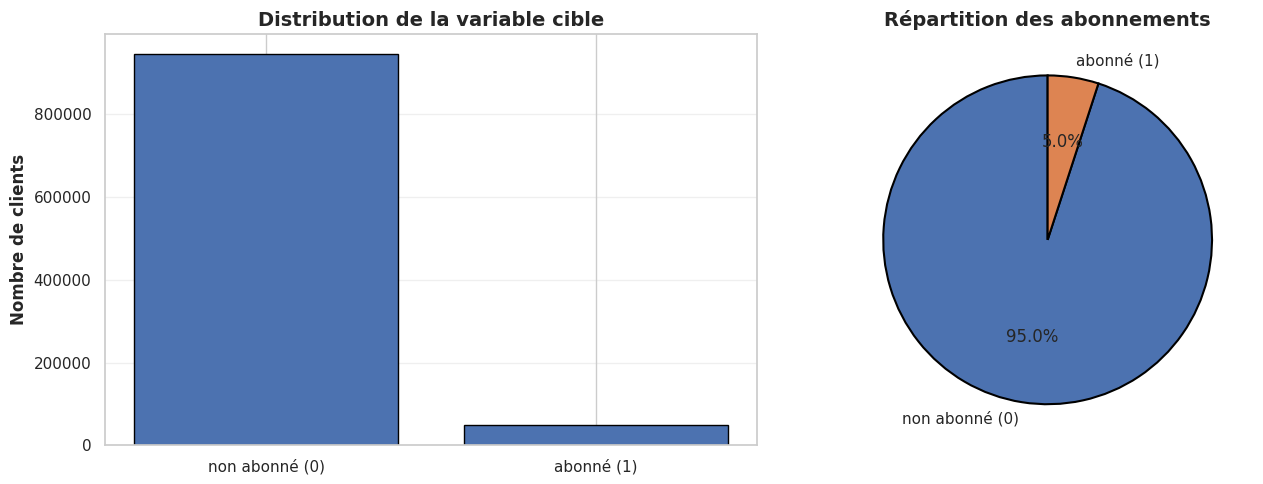

In [162]:
# Distribution de la variable cible
target_counts = df['subscribed_after'].value_counts()
target_percentage = df['subscribed_after'].value_counts(normalize=True) * 100

print("Distribution de la variable cible 'subscribed_after':")
print("="*80)
print(f"\nNombre de clients non abonné (0): {target_counts[0]} ({target_percentage[0]:.2f}%)")
print(f"Nombre de clients abonné (1): {target_counts[1]} ({target_percentage[1]:.2f}%)")

# Visualisation
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar plot
axes[0].bar(['non abonné (0)', 'abonné (1)'], target_counts.values, edgecolor='black')
axes[0].set_ylabel('Nombre de clients', fontsize=12, fontweight='bold')
axes[0].set_title('Distribution de la variable cible', fontsize=14, fontweight='bold')
axes[0].grid(axis='y', alpha=0.3)

# Pie chart

axes[1].pie(target_counts.values, labels=['non abonné (0)', 'abonné (1)'],
           autopct='%1.1f%%', startangle=90,
           wedgeprops={'edgecolor': 'black', 'linewidth': 1.5})
axes[1].set_title('Répartition des abonnements', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

*Analyse des variables categoriques*

In [163]:
categorical_cols = ["category", "device"]

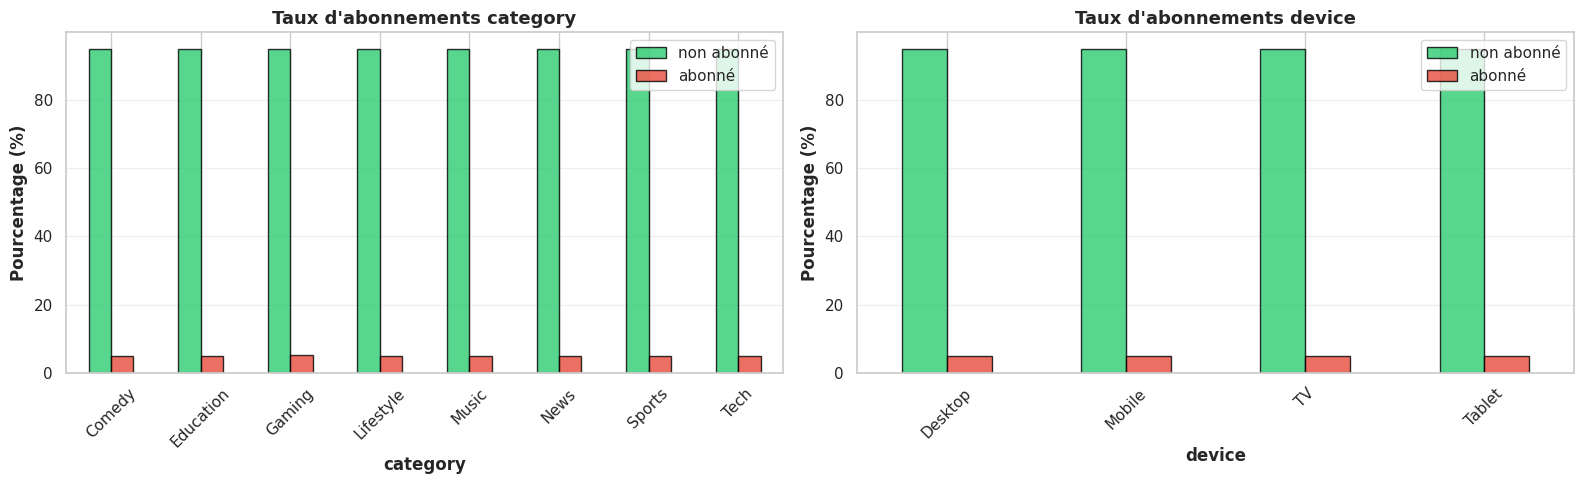

In [164]:
# Visualization de la distribution des variables numérique
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for idx, col in enumerate(categorical_cols):
    # Créer un crosstab
    ct = pd.crosstab(df[col], df['subscribed_after'], normalize='index') * 100

    # Bar plot empilé
    ct.plot(kind='bar', stacked=False, ax=axes[idx],
            color=['#2ecc71', '#e74c3c'], alpha=0.8, edgecolor='black')
    axes[idx].set_ylabel('Pourcentage (%)', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel(col, fontsize=12, fontweight='bold')
    axes[idx].set_title(f"Taux d'abonnements {col}", fontsize=13, fontweight='bold')
    axes[idx].legend(['non abonné', 'abonné'], loc='upper right')
    axes[idx].grid(axis='y', alpha=0.3)
    axes[idx].set_xticklabels(axes[idx].get_xticklabels(), rotation=45)

plt.tight_layout()
plt.show()

*Analyse des variables numériques*

In [165]:
numerical_cols = df.select_dtypes(include=['float64']).columns.tolist()

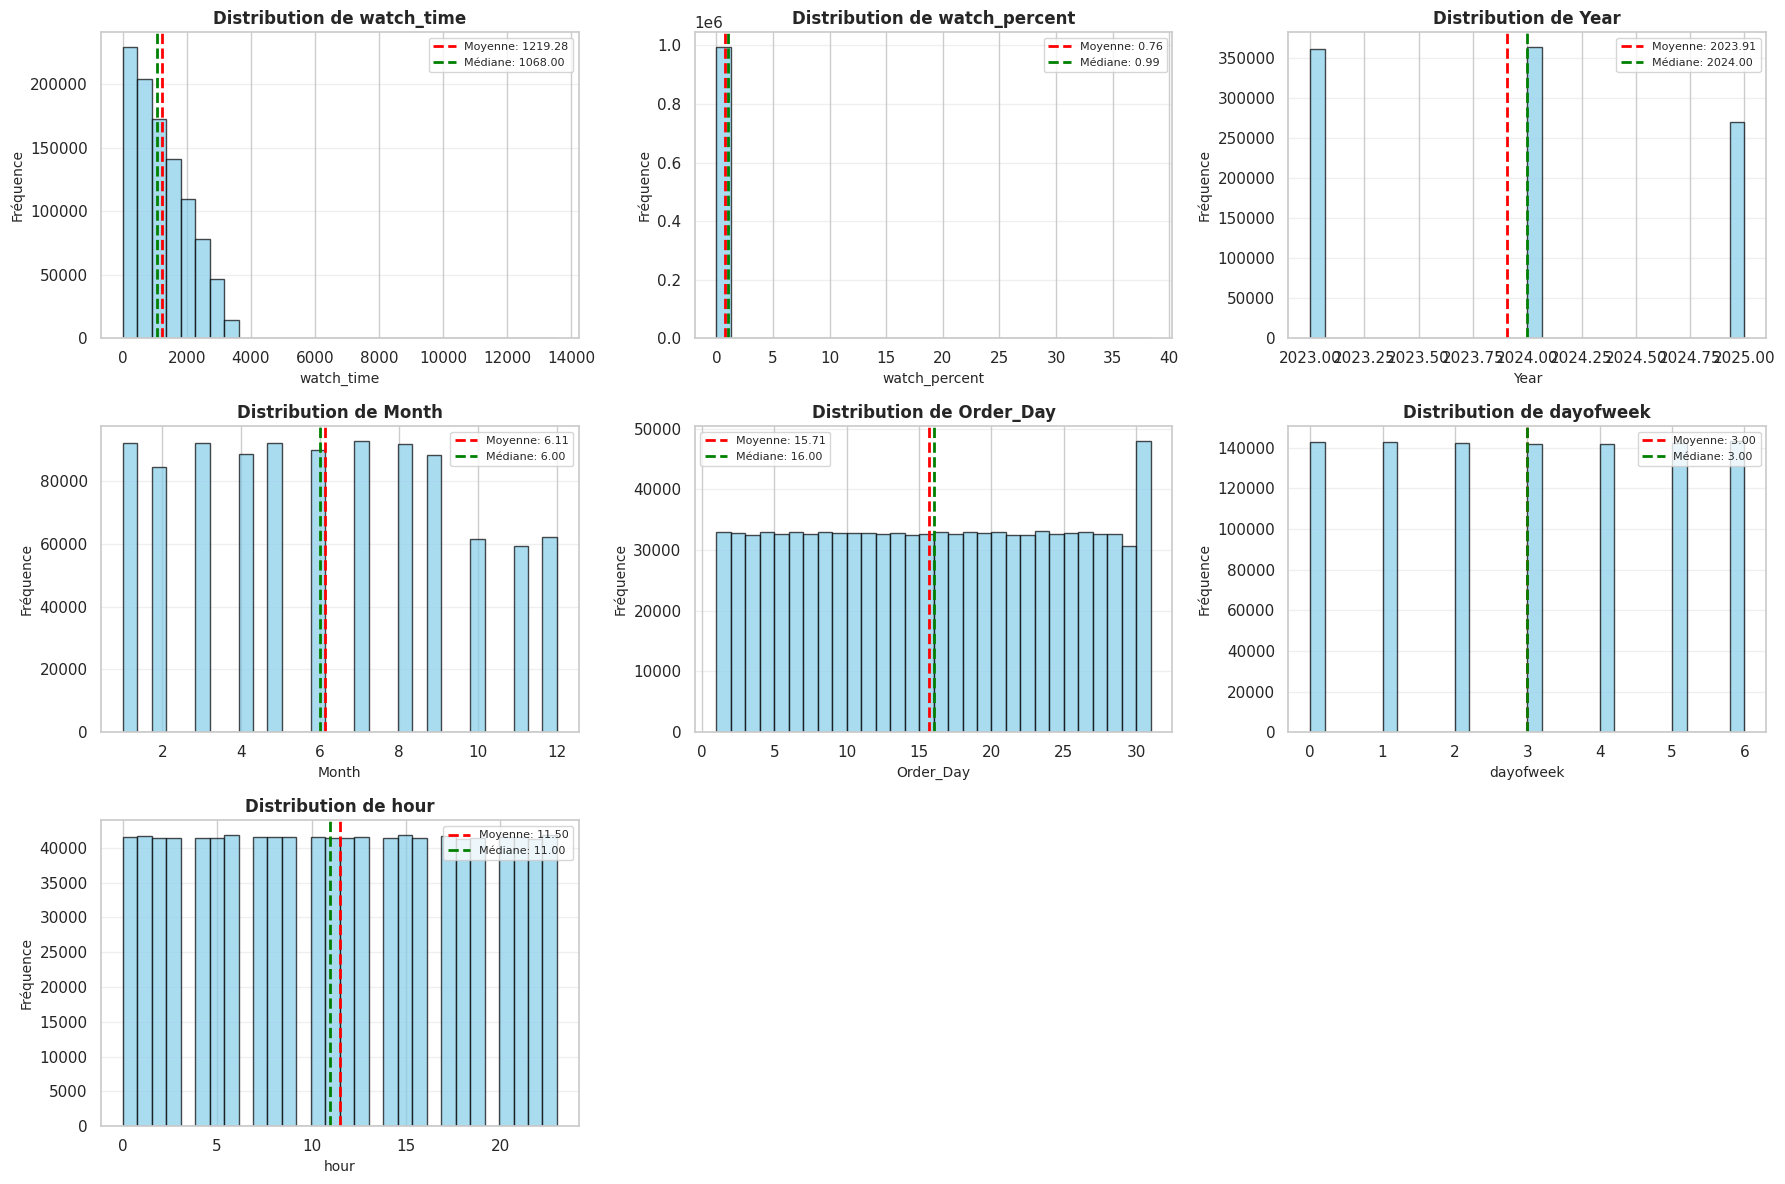

In [166]:
import math


# Définir le nombre de colonnes de la grille de visualisation
n_cols = 3
n_rows = math.ceil(len(numerical_cols) / n_cols)

fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(18, 4 * n_rows))
axes = axes.flatten()  # Aplatir la grille pour l'indexer facilement avec une boucle simple

for idx, col in enumerate(numerical_cols):
    ax = axes[idx]
    ax.hist(df[col], bins=30, color='skyblue', alpha=0.7, edgecolor='black')
    ax.set_title(f'Distribution de {col}', fontsize=12, fontweight='bold')
    ax.set_xlabel(col, fontsize=10)
    ax.set_ylabel('Fréquence', fontsize=10)
    ax.grid(axis='y', alpha=0.3)

    # Statistiques clés
    mean_val = df[col].mean()
    median_val = df[col].median()
    ax.axvline(mean_val, color='red', linestyle='--', linewidth=2, label=f'Moyenne: {mean_val:.2f}')
    ax.axvline(median_val, color='green', linestyle='--', linewidth=2, label=f'Médiane: {median_val:.2f}')
    ax.legend(fontsize=8)

# Masquer les sous-graphiques vides s'il y en a
for idx in range(len(numerical_cols), len(axes)):
    fig.delaxes(axes[idx])

plt.tight_layout()
plt.show()

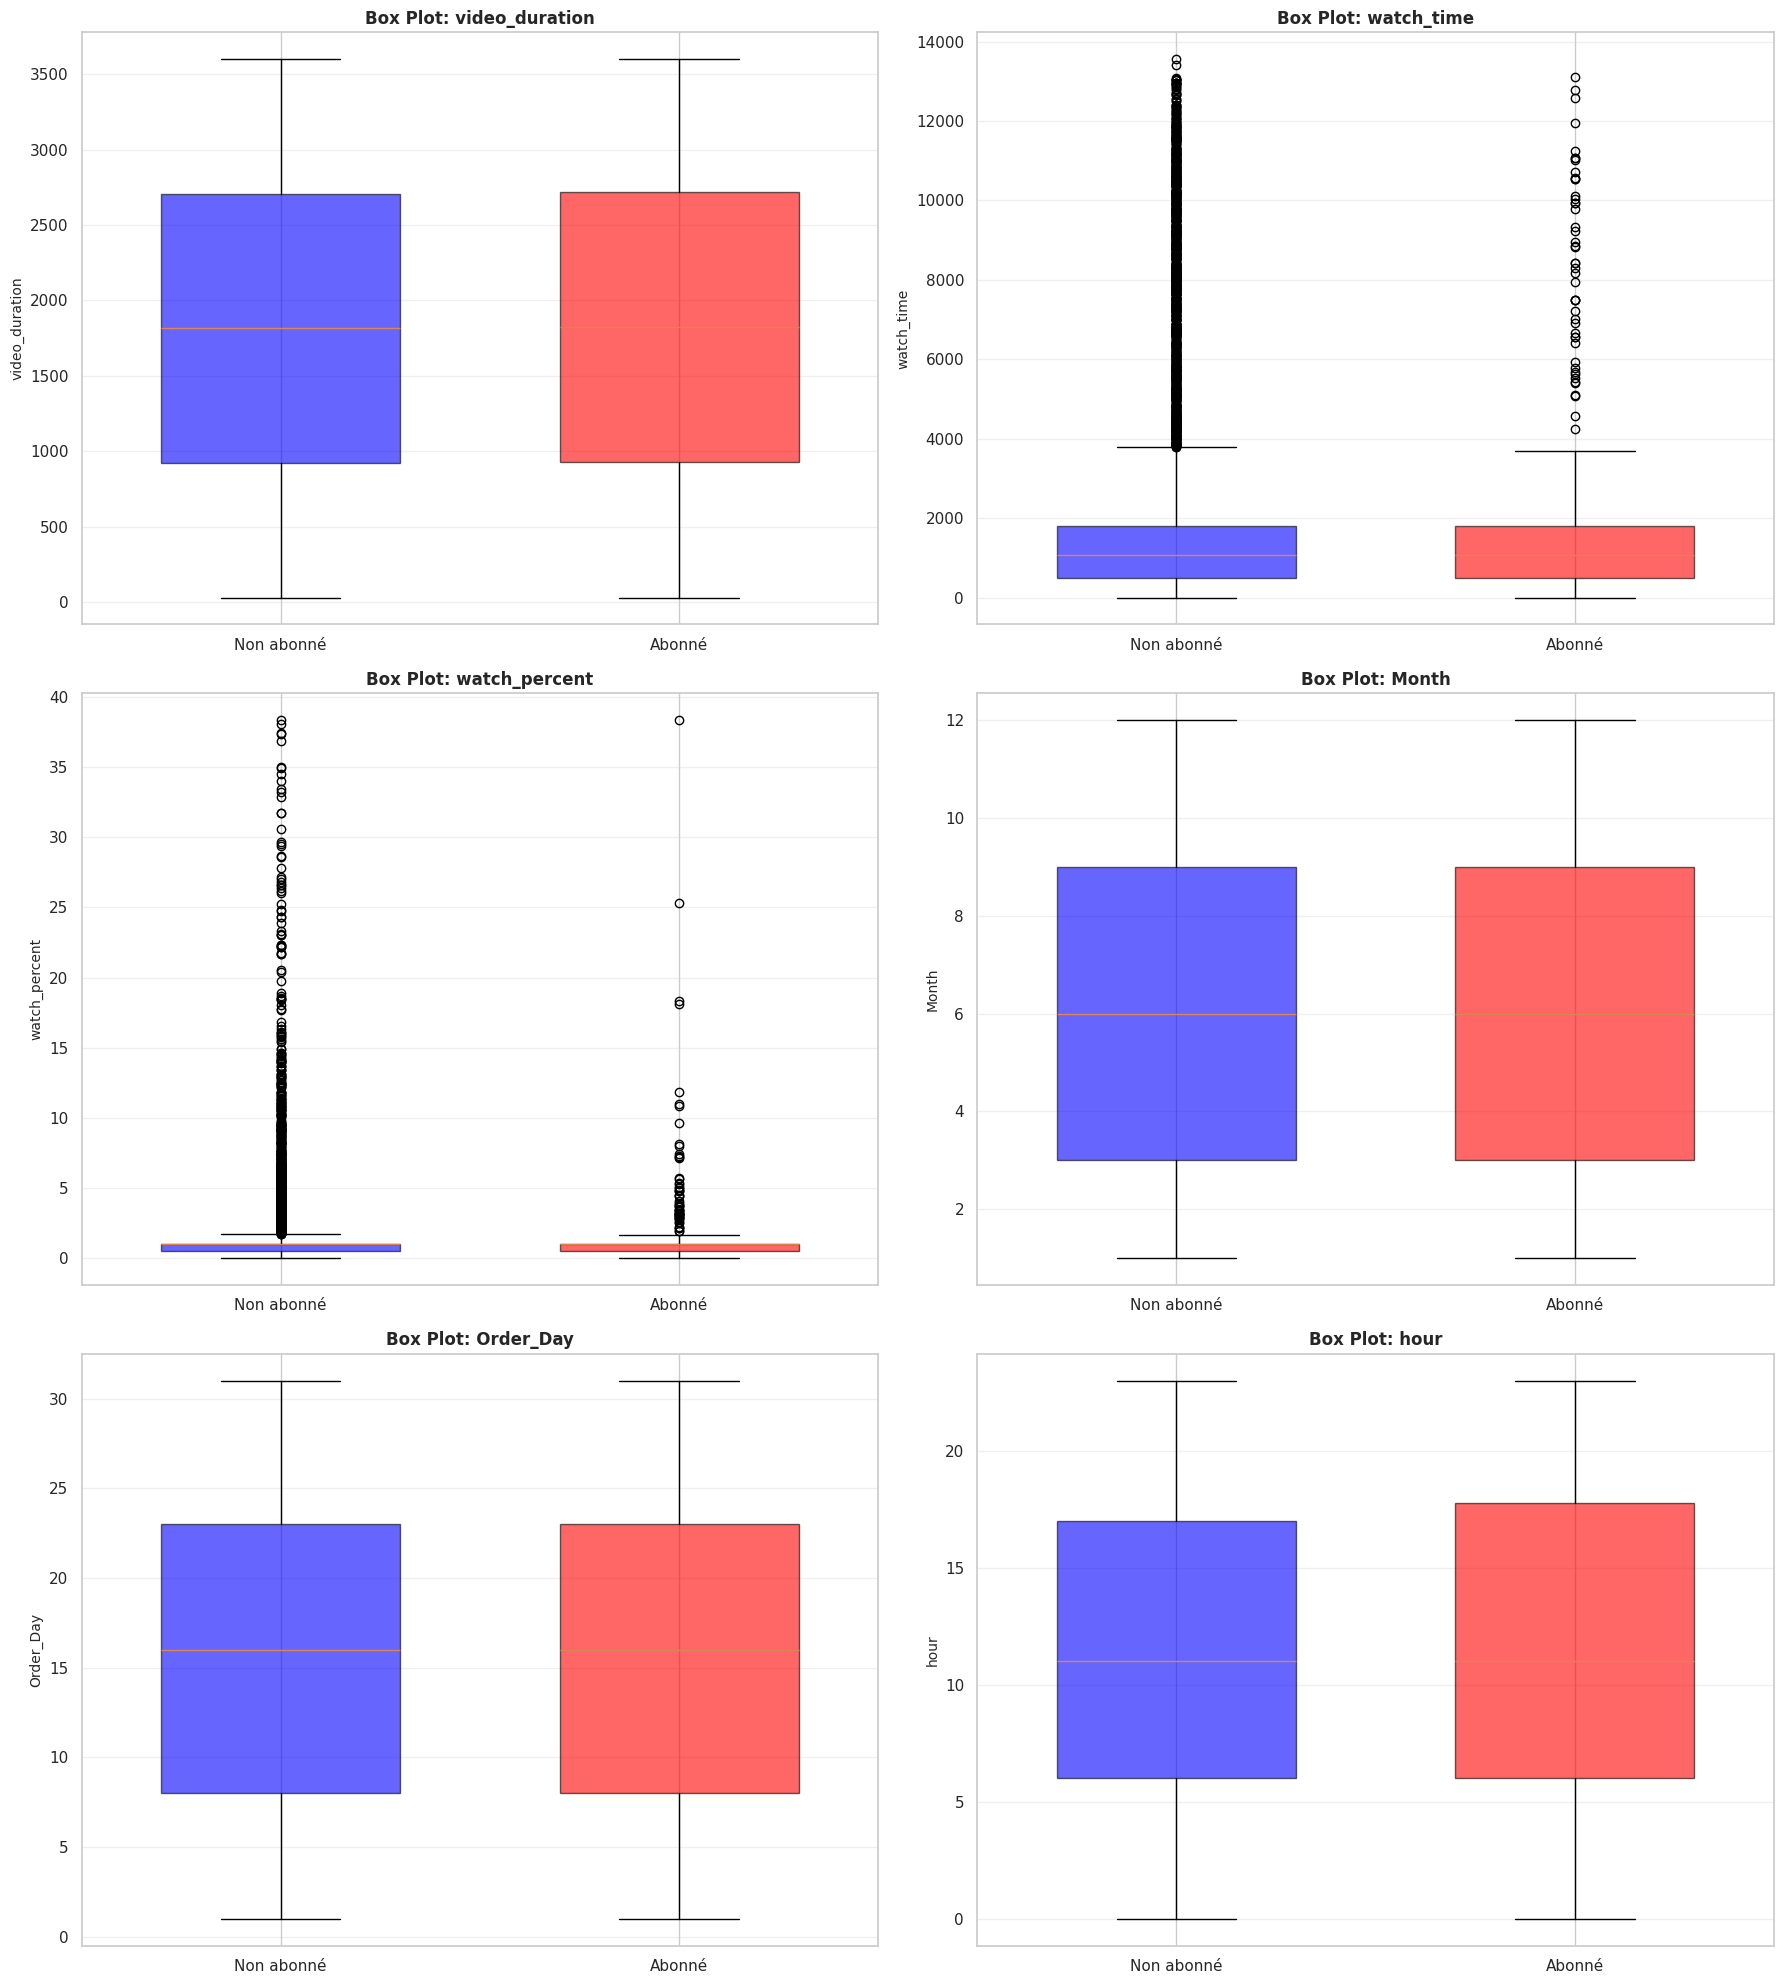

In [167]:
# Sélectionner toutes les colonnes de type int64 ou float64 pour la nouvelle liste de variables numériques
new_numeric = ['video_duration', 'watch_time', 'watch_percent', 'Month', 'Order_Day', 'hour']

fig, axes = plt.subplots(3, 2, figsize=(18, 20))
axes = axes.ravel() # Aplatir la matrice d'axes pour pouvoir l'indexer de 0 à 5

for idx, col in enumerate(new_numeric):
    bp = axes[idx].boxplot([
        df[df['subscribed_after'] == 0][col].dropna(),
        df[df['subscribed_after'] == 1][col].dropna()
    ],
    tick_labels=['Non abonné', 'Abonné'],
    patch_artist=True,
    widths=0.6)

    # Colorer les box plots (bleu pour non abonné, rouge pour abonné)
    colors = ['blue', 'red']
    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.6)

    axes[idx].set_title(f'Box Plot: {col}', fontsize=12, fontweight='bold')
    axes[idx].set_ylabel(col, fontsize=10)
    axes[idx].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

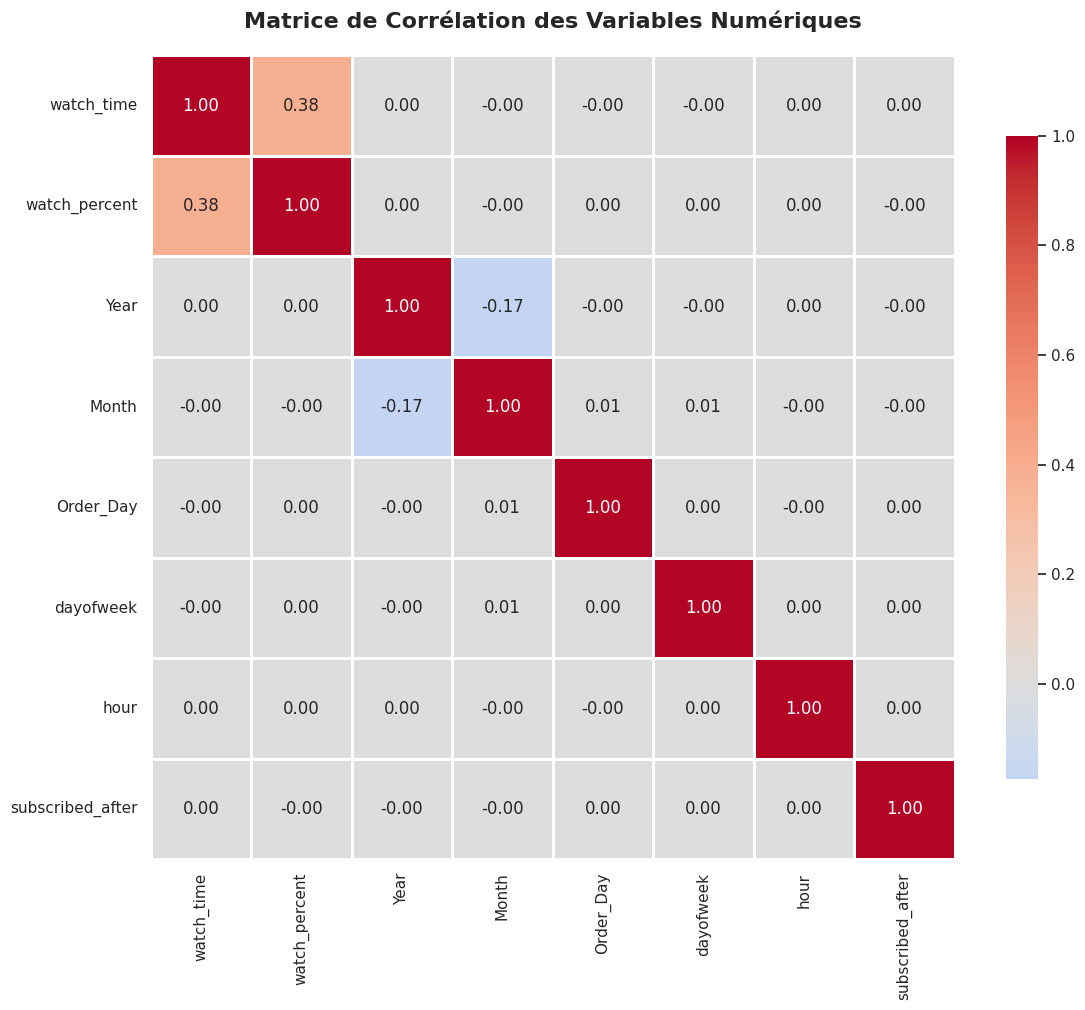


Corrélation avec la variable cible 'subscribed_after':
dayofweek        0.000969
hour             0.000375
Order_Day        0.000319
watch_time       0.000115
watch_percent   -0.000280
Year            -0.000379
Month           -0.000706
Name: subscribed_after, dtype: float64


In [168]:
# Définir l'ensemble des colonnes numériques pour la corrélation
correlation_cols = [col for col in numerical_cols if col in df.columns] + ['subscribed_after']

# Calculer la matrice de corrélation
corr_matrix = df[correlation_cols].corr()

# Dessiner la Heatmap complète
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, square=True, linewidths=1, cbar_kws={"shrink": 0.8})
plt.title('Matrice de Corrélation des Variables Numériques', fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

# Corrélation avec la variable cible 'subscribed_after'
print("\nCorrélation avec la variable cible 'subscribed_after':")
print("="*80)
target_corr = corr_matrix['subscribed_after'].sort_values(ascending=False)
print(target_corr[target_corr.index != 'subscribed_after'])


=== Nombre d'abonnés et non-abonnés par année ===


subscribed_after,0,1
Year,,
2023,343712,18150
2024,345740,18147
2025,257066,13521


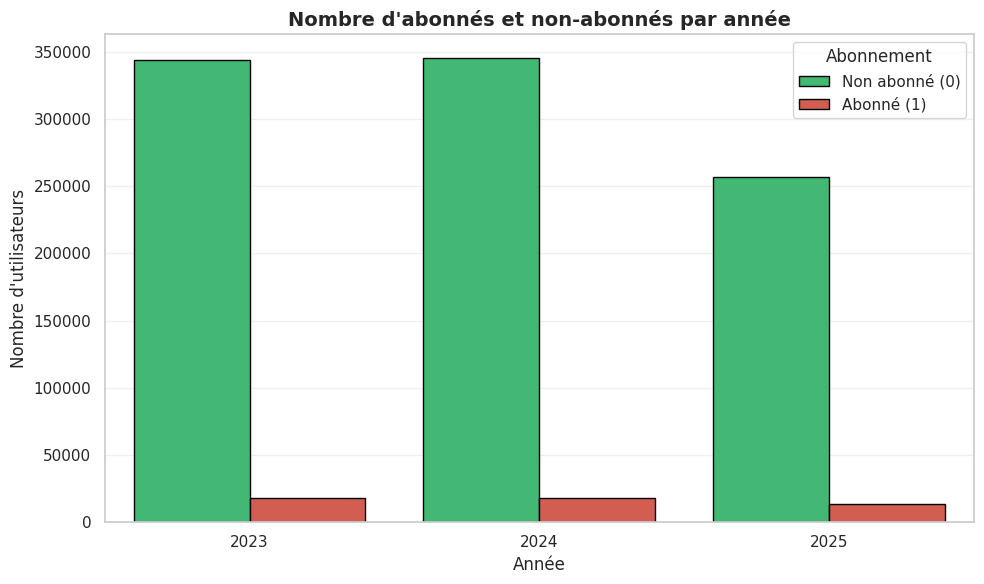

In [169]:
# Filtrer les données pour exclure d'éventuelles valeurs NaN dans 'Year'
df_year = df.dropna(subset=['Year']).copy()
df_year['Year'] = df_year['Year'].astype(int)

# Créer un tableau croisé des effectifs par année et statut d'abonnement
year_subscription = pd.crosstab(df_year['Year'], df_year['subscribed_after'])
print("=== Nombre d'abonnés et non-abonnés par année ===")
display(year_subscription)

# Visualisation sous forme de graphique de barres groupées
plt.figure(figsize=(10, 6))
sns.countplot(
    data=df_year,
    x='Year',
    hue='subscribed_after',
    palette={0: '#2ecc71', 1: '#e74c3c'},
    edgecolor='black'
)

plt.title("Nombre d'abonnés et non-abonnés par année", fontsize=14, fontweight='bold')
plt.xlabel("Année", fontsize=12)
plt.ylabel("Nombre d'utilisateurs", fontsize=12)
plt.legend(title="Abonnement", labels=['Non abonné (0)', 'Abonné (1)'])
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## Data Preprocessing

In [170]:
# Utiliser les transformation onehotencoder ou dummies sur les colonnes categorique (device et category)
from sklearn.preprocessing import OneHotEncoder
cols = ["device", "category"]
"""
enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=int)
encoded = enc.fit_transform(df[cols])

encoded_df = pd.DataFrame(encoded, columns=enc.get_feature_names_out(cols), index=df.index)
df_encoded = pd.concat([df.drop(columns=cols), encoded_df], axis=1)
"""
df = pd.get_dummies(df, columns=cols,prefix =["dev", "cat"], drop_first = True, dtype= int )

In [171]:
import numpy as np
# 2. Cyclical encoding (hour 23 is close to hour 0)
df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24).round(2)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24).round(2)
df["month_sin"] = np.sin(2 * np.pi * df["Month"] / 12).round(2)
df["month_cos"] = np.cos(2 * np.pi * df["Month"] / 12).round(2)
df["dow_sin"] = np.sin(2 * np.pi * df["dayofweek"] / 7).round(2)
df["dow_cos"] = np.cos(2 * np.pi * df["dayofweek"] / 7).round(2)

In [172]:
df.head()

,video_duration,watch_time,liked,commented,subscribed_after,recommended,clicked,watch_percent,timestamp_dt,date,...,cat_Music,cat_News,cat_Sports,cat_Tech,hour_sin,hour_cos,month_sin,month_cos,dow_sin,dow_cos
0,1499,1499.0,1,0,0,0,0,1.000000,2025-07-16 06:10:54,2025-07-16,...,0,1,0,0,1.00,0.00,-0.50,-0.87,0.97,-0.22
1,2955,2955.0,1,0,0,1,1,1.000000,2024-07-09 10:22:22,2024-07-09,...,0,0,0,0,0.50,-0.87,-0.50,-0.87,0.78,0.62
2,389,389.0,0,0,0,0,0,1.000000,2025-02-07 09:46:36,2025-02-07,...,0,0,1,0,0.71,-0.71,0.87,0.50,-0.43,-0.90
3,1231,1231.0,1,1,0,0,0,1.000000,2024-04-28 08:07:13,2024-04-28,...,0,0,0,0,0.87,-0.50,0.87,-0.50,-0.78,0.62
4,3573,353.0,0,1,0,1,0,0.098797,2024-03-30 12:54:24,2024-03-30,...,0,0,0,0,0.00,-1.00,1.00,0.00,-0.97,-0.22


In [173]:
# Supprimer les colonne ('hour', 'Month', 'dayofweek', 'timestamp_dt', 'date', 'time', 'Year_Month')
drop_cols = ['hour', 'Month', 'dayofweek', 'timestamp_dt', 'date', 'time', 'Year_Month']
df = df.drop(columns = drop_cols , axis = 1)

In [174]:
print("DataFrame Final pour la manipulation avec les colonnes :\n", df.columns)

DataFrame Final pour la manipulation avec les colonnes :
 Index(['video_duration', 'watch_time', 'liked', 'commented',
       'subscribed_after', 'recommended', 'clicked', 'watch_percent', 'Year',
       'Order_Day', 'Is_Weekend', 'dev_Mobile', 'dev_TV', 'dev_Tablet',
       'cat_Education', 'cat_Gaming', 'cat_Lifestyle', 'cat_Music', 'cat_News',
       'cat_Sports', 'cat_Tech', 'hour_sin', 'hour_cos', 'month_sin',
       'month_cos', 'dow_sin', 'dow_cos'],
      dtype='object')


## Train Test Split & Scaling

In [175]:
X = df.drop("subscribed_after", axis = 1)
y = df["subscribed_after"]

In [176]:
print(f"Shape de X: {X.shape}")
print(f"Shape de y: {y.shape}")
print(f"\nNombre de features: {X.shape[1]}")
print(f"\nListe des features:")
print(X.columns.tolist())

Shape de X: (996336, 26)
Shape de y: (996336,)

Nombre de features: 26

Liste des features:
['video_duration', 'watch_time', 'liked', 'commented', 'recommended', 'clicked', 'watch_percent', 'Year', 'Order_Day', 'Is_Weekend', 'dev_Mobile', 'dev_TV', 'dev_Tablet', 'cat_Education', 'cat_Gaming', 'cat_Lifestyle', 'cat_Music', 'cat_News', 'cat_Sports', 'cat_Tech', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'dow_sin', 'dow_cos']


In [177]:
# Split des données
# stratify : garder les proportion de la base de données (20% , 80%)
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Split des données (80% train - 20% test):")
print("="*80)
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

print("\nDistribution de la variable cible:")
print(f"Train - non abonné: {(y_train==0).sum()} ({(y_train==0).sum()/len(y_train)*100:.2f}%)")
print(f"Train - abonné: {(y_train==1).sum()} ({(y_train==1).sum()/len(y_train)*100:.2f}%)")
print(f"Test - non abonné: {(y_test==0).sum()} ({(y_test==0).sum()/len(y_test)*100:.2f}%)")
print(f"Test - abonné: {(y_test==1).sum()} ({(y_test==1).sum()/len(y_test)*100:.2f}%)")

Split des données (80% train - 20% test):
X_train shape: (797068, 26)
X_test shape: (199268, 26)
y_train shape: (797068,)
y_test shape: (199268,)

Distribution de la variable cible:
Train - non abonné: 757214 (95.00%)
Train - abonné: 39854 (5.00%)
Test - non abonné: 189304 (95.00%)
Test - abonné: 9964 (5.00%)


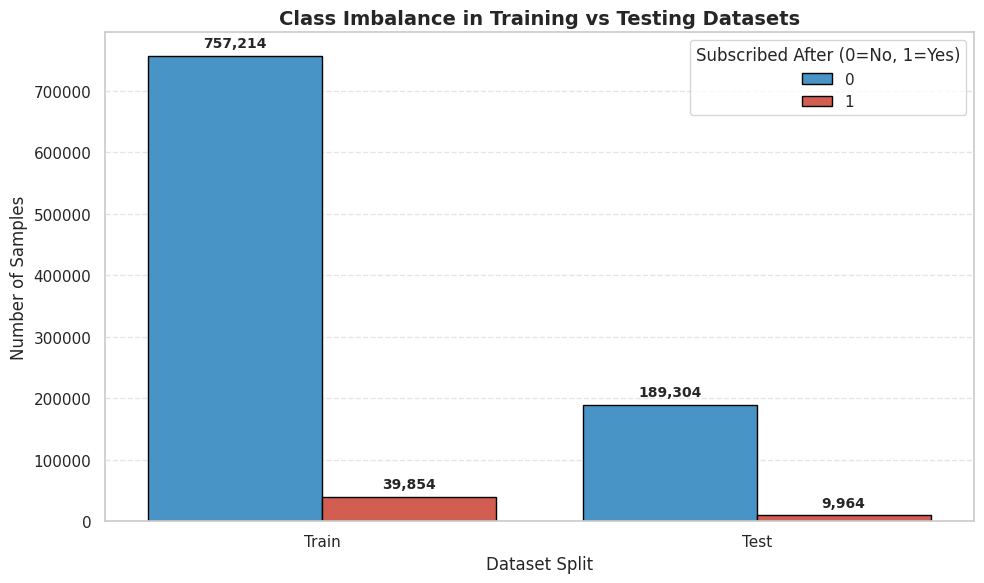

In [178]:
# Create a DataFrame for visualization
train_dist = pd.DataFrame({
    'Subscribed': y_train.values,
    'Dataset': 'Train'
})
test_dist = pd.DataFrame({
    'Subscribed': y_test.values,
    'Dataset': 'Test'
})
combined_dist = pd.concat([train_dist, test_dist])

# Plot the distribution
plt.figure(figsize=(10, 6))
sns.countplot(
    data=combined_dist,
    x='Dataset',
    hue='Subscribed',
    palette={0: '#3498db', 1: '#e74c3c'},
    edgecolor='black'
)

# Add details to the plot
plt.title("Class Imbalance in Training vs Testing Datasets", fontsize=14, fontweight='bold')
plt.xlabel("Dataset Split", fontsize=12)
plt.ylabel("Number of Samples", fontsize=12)
plt.legend(title="Subscribed After (0=No, 1=Yes)")
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Show actual numbers on top of the bars
ax = plt.gca()
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{int(height):,}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='center',
                    xytext=(0, 9),
                    textcoords='offset points',
                    fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

In [179]:
# Standardisation des features
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Normalisation effectuée avec StandardScaler")
print("="*80)
print("\nStatistiques après normalisation (X_train):")
print(f"Moyenne: {X_train_scaled.mean(axis=0).mean():.6f}")
print(f"Écart-type: {X_train_scaled.std(axis=0).mean():.6f}")

# Conversion en DataFrame pour plus de clarté
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X.columns)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=X.columns)

Normalisation effectuée avec StandardScaler

Statistiques après normalisation (X_train):
Moyenne: 0.000000
Écart-type: 1.000000


# Gestion du probléme du DataSet déséquilibrée

In [185]:
from imblearn.over_sampling import ADASYN
from imblearn.under_sampling import NearMiss
from imblearn.combine import SMOTEENN
from collections import Counter

def Handel_imbalance_data(X_train, y_tain):
    print("Original train Shape : X_train :", X_train.shape[0])
    print("Original Train Distribution", Counter(y_train))

    # OverSampling with ADASYN
    print("Applying ADASYN")
    adasyn = ADASYN(sampling_strategy=0.7, random_state=42, )
    X_train_adasyn, y_train_adasyn = adasyn.fit_resample(X_train, y_train)
    print("ADASYN train Shape : X_train :", X_train_adasyn.shape[0])
    print("Distribution after Over Sampling", Counter(y_train_adasyn))

    # UnderSampling with NearMiss
    print("Applying NearMiss")
    nm = NearMiss(sampling_strategy=0.5, version=1)
    X_train_nm, y_train_nm = nm.fit_resample(X_train, y_train)
    print("UnderSampling train Shape : X_train :", X_train_nm.shape[0])
    print("Distribution after Under Sampling", Counter(y_train_nm))


    return {
        "original": (X_train, y_train),
        "UnderSampling": (X_train_nm, y_train_nm),
        "OverSampling": (X_train_adasyn, y_train_adasyn)
    }

In [186]:
"""
    # Combine OverSampling and UnderSampling
    print("Applying ADASYN then NearMiss")
    nm_combine = NearMiss(sampling_strategy=1, version=1)
    X_train_comb, y_train_comb = nm_combine.fit_resample(X_train_adasyn, y_train_adasyn)
    print("Combined train Shape : X_train :", X_train_comb.shape[0])
    print("Distribution after combine", Counter(y_train_comb))
"""

'\n    # Combine OverSampling and UnderSampling\n    print("Applying ADASYN then NearMiss")\n    nm_combine = NearMiss(sampling_strategy=1, version=1)\n    X_train_comb, y_train_comb = nm_combine.fit_resample(X_train_adasyn, y_train_adasyn)\n    print("Combined train Shape : X_train :", X_train_comb.shape[0])\n    print("Distribution after combine", Counter(y_train_comb))\n'

In [187]:
# Création de la fonction d'evaluation des modèles

In [188]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    roc_curve, precision_recall_curve, auc
)
from sklearn.base import clone

def evaluate_model(name, model_inst, datasets, X_test_raw, y_test_raw):
    """
    Fonction pour évaluer un modèle avec différentes techniques de rééchantillonnage (Sampling).
    Génère un tableau comparatif, affiche la matrice de confusion, et trace les courbes ROC et PR pour chaque méthode.
    """

    results_list = []
    predictions_proba = {}
    predictions_labels = {}

    # 2. Entraînement et évaluation pour chaque stratégie
    for strategy_name, (X_tr, y_tr) in datasets.items():
        print(f"\nEntraînement du modèle [{name}] avec la stratégie : {strategy_name} en cours...")
        # Cloner le modèle pour chaque entraînement indépendant

        model = clone(model_inst)
        model.fit(X_tr, y_tr)

        # Prédictions
        y_pred_train = model.predict(X_tr)
        y_pred_test = model.predict(X_test_raw)

        # Probabilités pour ROC-AUC et PR
        if hasattr(model, 'predict_proba'):
            y_pred_proba = model.predict_proba(X_test_raw)[:, 1]
        else:
            y_pred_proba = model.decision_function(X_test_raw) if hasattr(model, 'decision_function') else None

        if y_pred_proba is not None:
            roc_auc = roc_auc_score(y_test_raw, y_pred_proba)
            predictions_proba[strategy_name] = y_pred_proba
        else:
            roc_auc = None

        predictions_labels[strategy_name] = y_pred_test

        # Enregistrement des résultats
        results = {
            'Modèle': f"{name} ({strategy_name})",
            'Sampling': strategy_name,
            'Accuracy Train': accuracy_score(y_tr, y_pred_train),
            'Accuracy Test': accuracy_score(y_test_raw, y_pred_test),
            'Precision': precision_score(y_test_raw, y_pred_test, zero_division=0),
            'Recall': recall_score(y_test_raw, y_pred_test, zero_division=0),
            'F1-Score': f1_score(y_test_raw, y_pred_test, zero_division=0),
            'ROC-AUC': roc_auc
        }
        results_list.append(results)

        # Affichage synthétique par stratégie
        print(f"Accuracy Test: {results['Accuracy Test']:.4f} | Precision: {results['Precision']:.4f} | Recall: {results['Recall']:.4f} | F1: {results['F1-Score']:.4f}")

    # 3. Création et affichage du DataFrame de comparaison
    df_results = pd.DataFrame(results_list)
    print("\n" + "="*100)
    print(f"TABLEAU COMPARATIF POUR LE MODÈLE : {name}")
    print("="*100)
    display(df_results.round(4))

    # 4. Tracé des courbes ROC-AUC et Precision-Recall (PR) côte à côte
    fig, axes = plt.subplots(1, 2, figsize=(18, 7))
    colors = {
        'original': '#3498db',
        'UnderSampling': '#e67e22',
        'OverSampling': '#9b59b6',
        'combine': '#e74c3c'
    }

    # Graphique 1 : Courbe ROC
    for strategy_name, y_proba in predictions_proba.items():
        fpr, tpr, _ = roc_curve(y_test_raw, y_proba)
        score_auc = roc_auc_score(y_test_raw, y_proba)
        axes[0].plot(fpr, tpr, color=colors.get(strategy_name, '#bdc3c7'), lw=2,
                     label=f'{strategy_name} (AUC = {score_auc:.4f})')

    axes[0].plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--')
    axes[0].set_xlim([0.0, 1.0])
    axes[0].set_ylim([0.0, 1.05])
    axes[0].set_xlabel('Taux de faux positifs (FPR)', fontsize=12)
    axes[0].set_ylabel('Taux de vrais positifs (TPR)', fontsize=12)
    axes[0].set_title(f'Courbes ROC - {name}', fontsize=14, fontweight='bold')
    axes[0].legend(loc="lower right")
    axes[0].grid(True, linestyle='--', alpha=0.5)

    # Graphique 2 : Courbe Precision-Recall (PR)
    for strategy_name, y_proba in predictions_proba.items():
        precision, recall, _ = precision_recall_curve(y_test_raw, y_proba)
        score_pr_auc = auc(recall, precision)
        axes[1].plot(recall, precision, color=colors.get(strategy_name, '#bdc3c7'), lw=2,
                     label=f'{strategy_name} (AUC-PR = {score_pr_auc:.4f})')

    axes[1].set_xlim([0.0, 1.0])
    axes[1].set_ylim([0.0, 1.05])
    axes[1].set_xlabel('Recall', fontsize=12)
    axes[1].set_ylabel('Precision', fontsize=12)
    axes[1].set_title(f'Courbes Precision-Recall (PR) - {name}', fontsize=14, fontweight='bold')
    axes[1].legend(loc="lower left")
    axes[1].grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.show()

    # 5. Affichage des rapports de classification pour chaque stratégie
    print("\n" + "="*100)
    print("RAPPORTS DE CLASSIFICATION PAR STRATÉGIE (DONNÉES DE TEST ORIGINALES)")
    print("="*100)
    for strategy_name, y_pred in predictions_labels.items():
        print(f"\nRapport pour la stratégie : {strategy_name}")
        print("-" * 40)
        print(classification_report(y_test_raw, y_pred, target_names=['Non Abonné', 'Abonné'], zero_division=0))

    return results_list

# Modèlisation et Évaluation des Modèles

In [189]:
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
dict_models = {
        "RandomForest": RandomForestClassifier(
            n_estimators=200, max_depth=12, n_jobs=-1, random_state=42),
        "ExtraTrees": ExtraTreesClassifier(
            n_estimators=200, max_depth=12, n_jobs=-1, random_state=42),
        "XGBoost": XGBClassifier(
            n_estimators=200, max_depth=6, learning_rate=0.1,
            eval_metric="logloss", n_jobs=-1, random_state=42),
        "LightGBM": LGBMClassifier(
            n_estimators=200, learning_rate=0.1, n_jobs=-1,
            random_state=42, verbose=-1),
    }

dict_strategy = Handel_imbalance_data(X_train, y_train)

Original train Shape : X_train : 797068
Original Train Distribution Counter({0: 757214, 1: 39854})
Applying ADASYN
ADASYN train Shape : X_train : 1286157
Distribution after Over Sampling Counter({0: 757214, 1: 528943})
Applying NearMiss
UnderSampling train Shape : X_train : 119562
Distribution after Under Sampling Counter({0: 79708, 1: 39854})



Entraînement du modèle [RandomForest] avec la stratégie : original en cours...
Accuracy Test: 0.9500 | Precision: 0.0000 | Recall: 0.0000 | F1: 0.0000

Entraînement du modèle [RandomForest] avec la stratégie : UnderSampling en cours...
Accuracy Test: 0.0510 | Precision: 0.0500 | Recall: 0.9983 | F1: 0.0952

Entraînement du modèle [RandomForest] avec la stratégie : OverSampling en cours...
Accuracy Test: 0.8595 | Precision: 0.0515 | Recall: 0.1039 | F1: 0.0688

TABLEAU COMPARATIF POUR LE MODÈLE : RandomForest


,Modèle,Sampling,Accuracy Train,Accuracy Test,Precision,Recall,F1-Score,ROC-AUC
0,RandomForest (original),original,0.9500,0.9500,0.0000,0.0000,0.0000,0.4992
1,RandomForest (UnderSampling),UnderSampling,0.8564,0.0510,0.0500,0.9983,0.0952,0.5042
2,RandomForest (OverSampling),OverSampling,0.9543,0.8595,0.0515,0.1039,0.0688,0.5038


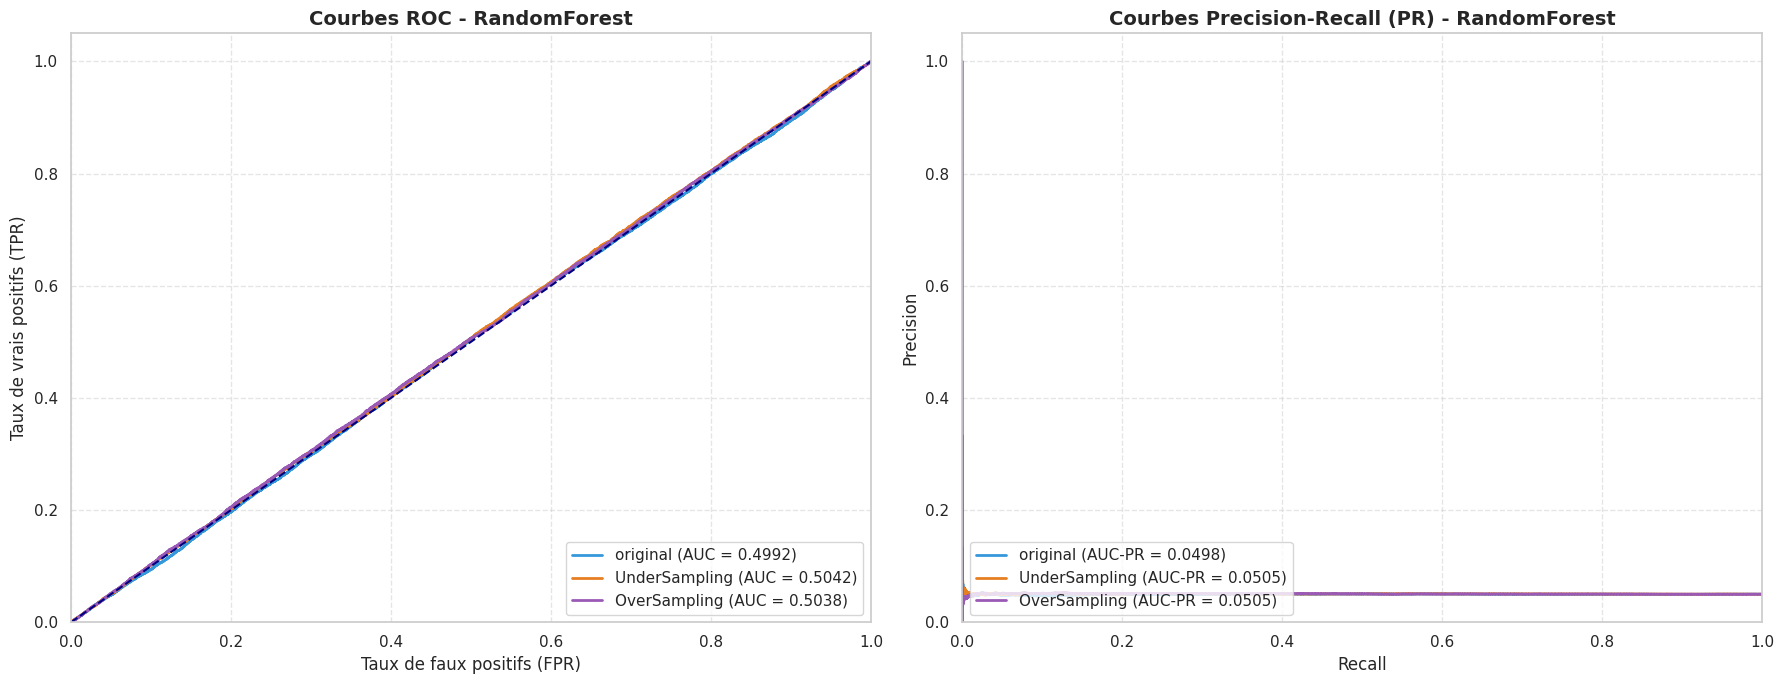


RAPPORTS DE CLASSIFICATION PAR STRATÉGIE (DONNÉES DE TEST ORIGINALES)

Rapport pour la stratégie : original
----------------------------------------
              precision    recall  f1-score   support

  Non Abonné       0.95      1.00      0.97    189304
      Abonné       0.00      0.00      0.00      9964

    accuracy                           0.95    199268
   macro avg       0.47      0.50      0.49    199268
weighted avg       0.90      0.95      0.93    199268


Rapport pour la stratégie : UnderSampling
----------------------------------------
              precision    recall  f1-score   support

  Non Abonné       0.93      0.00      0.00    189304
      Abonné       0.05      1.00      0.10      9964

    accuracy                           0.05    199268
   macro avg       0.49      0.50      0.05    199268
weighted avg       0.89      0.05      0.01    199268


Rapport pour la stratégie : OverSampling
----------------------------------------
              precision    re

,Modèle,Sampling,Accuracy Train,Accuracy Test,Precision,Recall,F1-Score,ROC-AUC
0,ExtraTrees (original),original,0.9500,0.9500,0.00,0.0000,0.0000,0.5026
1,ExtraTrees (UnderSampling),UnderSampling,0.8393,0.0831,0.05,0.9622,0.0950,0.5018
2,ExtraTrees (OverSampling),OverSampling,0.8882,0.8873,0.05,0.0697,0.0582,0.4981


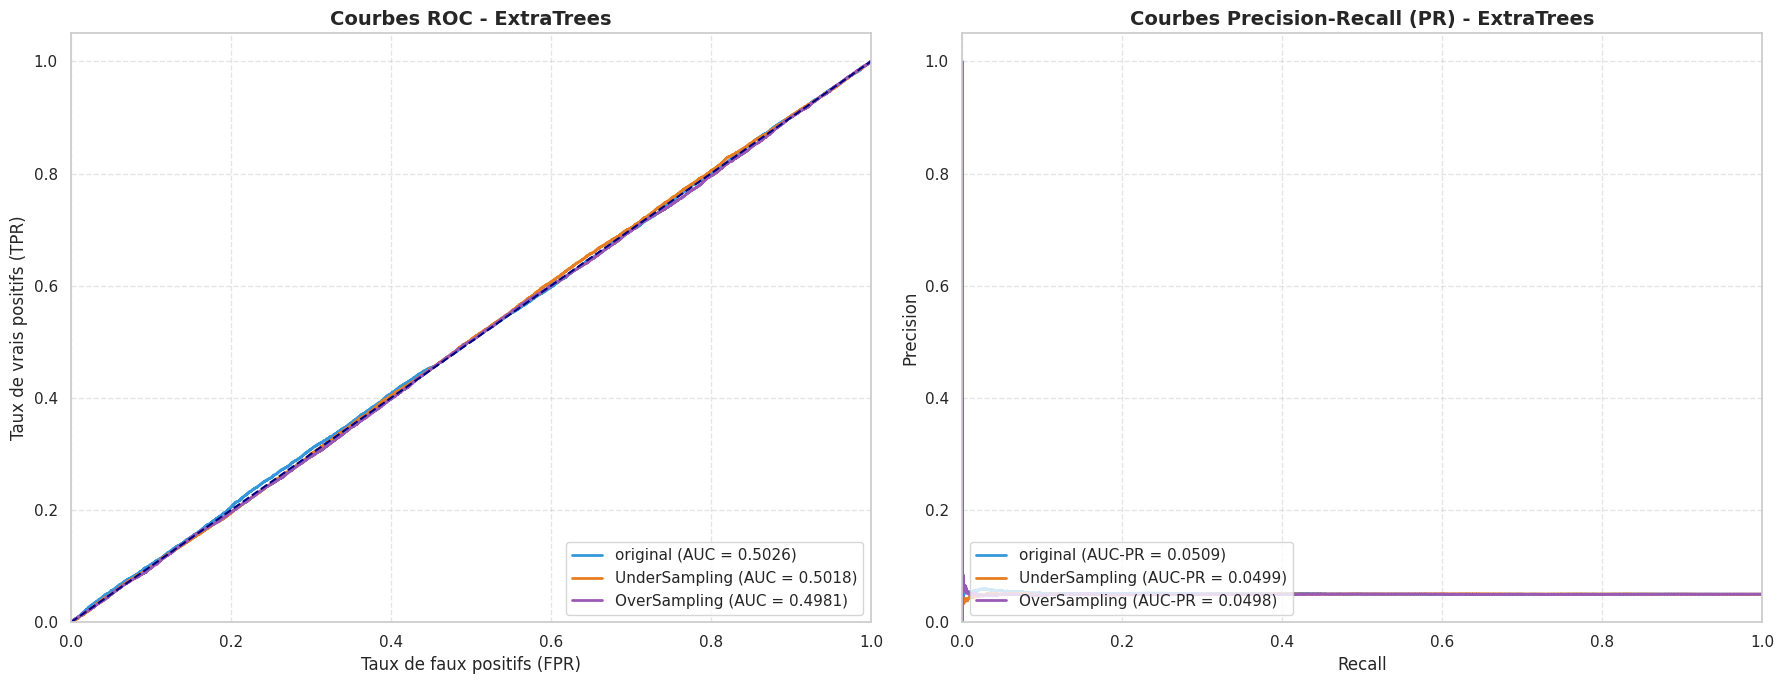


RAPPORTS DE CLASSIFICATION PAR STRATÉGIE (DONNÉES DE TEST ORIGINALES)

Rapport pour la stratégie : original
----------------------------------------
              precision    recall  f1-score   support

  Non Abonné       0.95      1.00      0.97    189304
      Abonné       0.00      0.00      0.00      9964

    accuracy                           0.95    199268
   macro avg       0.47      0.50      0.49    199268
weighted avg       0.90      0.95      0.93    199268


Rapport pour la stratégie : UnderSampling
----------------------------------------
              precision    recall  f1-score   support

  Non Abonné       0.95      0.04      0.07    189304
      Abonné       0.05      0.96      0.09      9964

    accuracy                           0.08    199268
   macro avg       0.50      0.50      0.08    199268
weighted avg       0.90      0.08      0.07    199268


Rapport pour la stratégie : OverSampling
----------------------------------------
              precision    re

,Modèle,Sampling,Accuracy Train,Accuracy Test,Precision,Recall,F1-Score,ROC-AUC
0,XGBoost (original),original,0.9500,0.9498,0.0500,0.0002,0.0004,0.4985
1,XGBoost (UnderSampling),UnderSampling,0.8529,0.0504,0.0500,0.9992,0.0952,0.4969
2,XGBoost (OverSampling),OverSampling,0.9688,0.0780,0.0501,0.9712,0.0953,0.4988


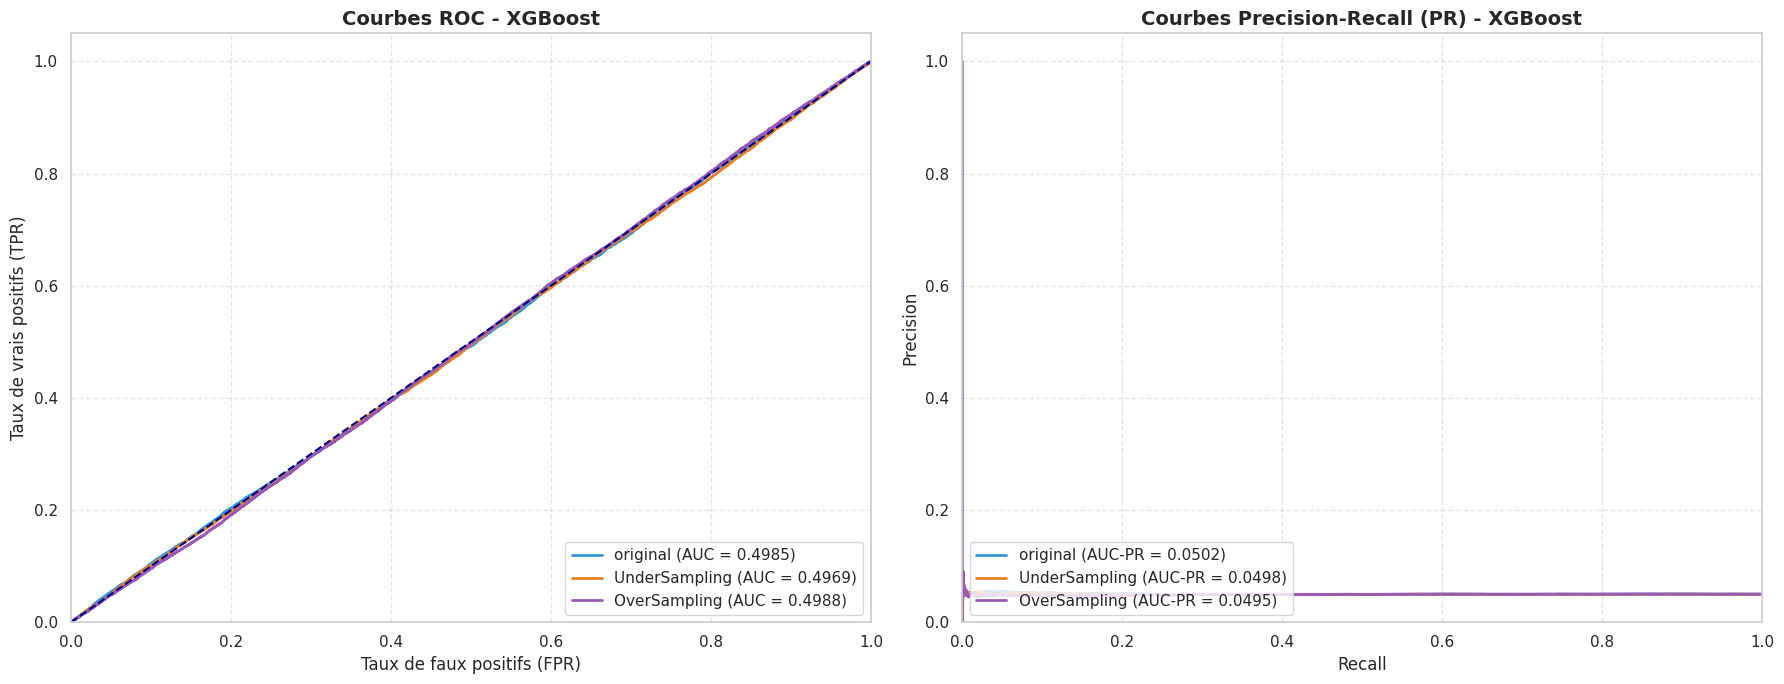


RAPPORTS DE CLASSIFICATION PAR STRATÉGIE (DONNÉES DE TEST ORIGINALES)

Rapport pour la stratégie : original
----------------------------------------
              precision    recall  f1-score   support

  Non Abonné       0.95      1.00      0.97    189304
      Abonné       0.05      0.00      0.00      9964

    accuracy                           0.95    199268
   macro avg       0.50      0.50      0.49    199268
weighted avg       0.90      0.95      0.93    199268


Rapport pour la stratégie : UnderSampling
----------------------------------------
              precision    recall  f1-score   support

  Non Abonné       0.91      0.00      0.00    189304
      Abonné       0.05      1.00      0.10      9964

    accuracy                           0.05    199268
   macro avg       0.48      0.50      0.05    199268
weighted avg       0.87      0.05      0.01    199268


Rapport pour la stratégie : OverSampling
----------------------------------------
              precision    re

,Modèle,Sampling,Accuracy Train,Accuracy Test,Precision,Recall,F1-Score,ROC-AUC
0,LightGBM (original),original,0.9500,0.9497,0.0370,0.0002,0.0004,0.5010
1,LightGBM (UnderSampling),UnderSampling,0.8533,0.0501,0.0500,0.9997,0.0952,0.4994
2,LightGBM (OverSampling),OverSampling,0.9688,0.2952,0.0501,0.7291,0.0938,0.4985


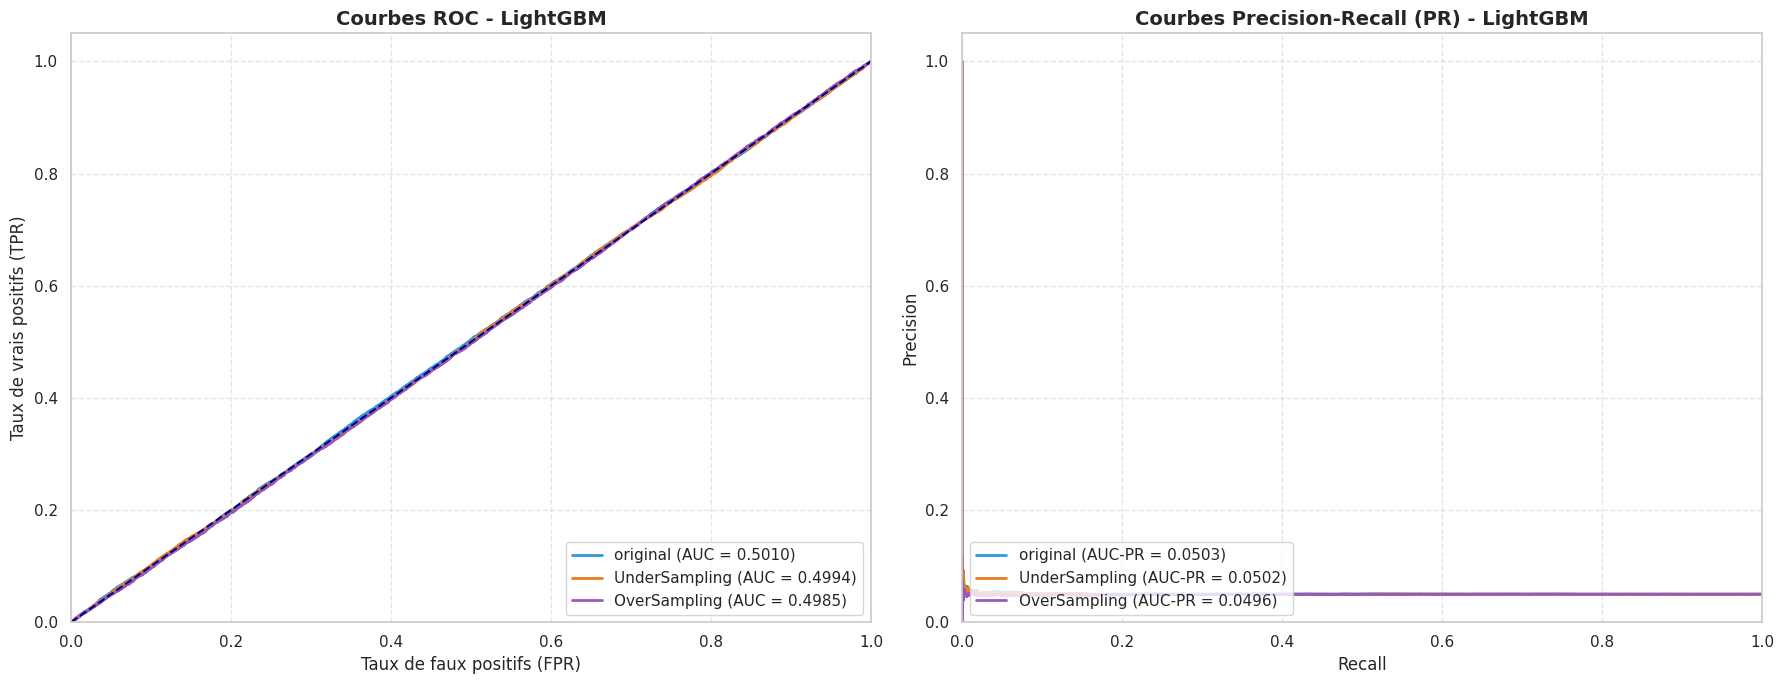


RAPPORTS DE CLASSIFICATION PAR STRATÉGIE (DONNÉES DE TEST ORIGINALES)

Rapport pour la stratégie : original
----------------------------------------
              precision    recall  f1-score   support

  Non Abonné       0.95      1.00      0.97    189304
      Abonné       0.04      0.00      0.00      9964

    accuracy                           0.95    199268
   macro avg       0.49      0.50      0.49    199268
weighted avg       0.90      0.95      0.93    199268


Rapport pour la stratégie : UnderSampling
----------------------------------------
              precision    recall  f1-score   support

  Non Abonné       0.91      0.00      0.00    189304
      Abonné       0.05      1.00      0.10      9964

    accuracy                           0.05    199268
   macro avg       0.48      0.50      0.05    199268
weighted avg       0.87      0.05      0.01    199268


Rapport pour la stratégie : OverSampling
----------------------------------------
              precision    re

In [191]:
all_results = []
X_test_df = pd.DataFrame(X_test_scaled, columns=X_train.columns)
for name, model_inst in dict_models.items():
  model_result = evaluate_model(name, model_inst, dict_strategy, X_test_df, y_test)
  all_results.extend(model_result)

In [192]:
import pandas as pd

# Conversion de la liste globale des résultats en DataFrame
df_all_results = pd.DataFrame(all_results)

# Tri du DataFrame par 'F1-Score' de manière décroissante
df_all_results_sorted = df_all_results.sort_values(by='F1-Score', ascending=False)

# Affichage des résultats
print("=== CLASSEMENT GLOBAL DES MODÈLES ET STRATÉGIES PAR F1-SCORE ===")
display(df_all_results_sorted.round(4))

=== CLASSEMENT GLOBAL DES MODÈLES ET STRATÉGIES PAR F1-SCORE ===


,Modèle,Sampling,Accuracy Train,Accuracy Test,Precision,Recall,F1-Score,ROC-AUC
8,XGBoost (OverSampling),OverSampling,0.9688,0.0780,0.0501,0.9712,0.0953,0.4988
10,LightGBM (UnderSampling),UnderSampling,0.8533,0.0501,0.0500,0.9997,0.0952,0.4994
7,XGBoost (UnderSampling),UnderSampling,0.8529,0.0504,0.0500,0.9992,0.0952,0.4969
1,RandomForest (UnderSampling),UnderSampling,0.8564,0.0510,0.0500,0.9983,0.0952,0.5042
4,ExtraTrees (UnderSampling),UnderSampling,0.8393,0.0831,0.0500,0.9622,0.0950,0.5018
11,LightGBM (OverSampling),OverSampling,0.9688,0.2952,0.0501,0.7291,0.0938,0.4985
2,RandomForest (OverSampling),OverSampling,0.9543,0.8595,0.0515,0.1039,0.0688,0.5038
5,ExtraTrees (OverSampling),OverSampling,0.8882,0.8873,0.0500,0.0697,0.0582,0.4981
6,XGBoost (original),original,0.9500,0.9498,0.0500,0.0002,0.0004,0.4985
9,LightGBM (original),original,0.9500,0.9497,0.0370,0.0002,0.0004,0.5010


In [193]:
Xa, Xb, ya, yb = train_test_split(X_train, y_train, test_size=0.2,
                                  stratify=y_train, random_state=42)
m = LGBMClassifier(n_estimators=200, verbose=-1).fit(Xa, ya)
print("val AUC:", roc_auc_score(yb, m.predict_proba(Xb)[:, 1]))

val AUC: 0.4998298975820988


In [194]:
print(X_train.index.equals(y_train.index))     # must be True
print(X_train.shape, y_train.shape)

True
(797068, 26) (797068,)


In [195]:

aucs = {c: roc_auc_score(y_train, X_train[c]) for c in X_train.select_dtypes("number").columns}
print((pd.Series(aucs) - 0.5).abs().sort_values(ascending=False).head(10))

month_cos     0.002775
dow_cos       0.002338
Order_Day     0.001891
cat_Music     0.001748
month_sin     0.001515
cat_Gaming    0.001216
clicked       0.001150
commented     0.001116
dev_Mobile    0.001091
dev_TV        0.001088
dtype: float64


In [198]:
d = df.loc[y_train.index]
print(d.groupby("liked")["subscribed_after"].mean())
print(d.groupby(pd.qcut(d["watch_percent"], 5, duplicates="drop"))["subscribed_after"].mean())
print("liked" in X_train.columns, "watch_percent" in X_train.columns)

liked
0    0.049979
1    0.050051
Name: subscribed_after, dtype: float64
watch_percent
(0.00041, 0.399]    0.049757
(0.399, 0.795]      0.050291
(0.795, 1.0]        0.050004
(1.0, 38.359]       0.041860
Name: subscribed_after, dtype: float64
True True


/tmp/ipykernel_1824/4100995672.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(d.groupby(pd.qcut(d["watch_percent"], 5, duplicates="drop"))["subscribed_after"].mean())


In [199]:
hi = d["watch_percent"] > 1
print(hi.sum(), len(d))
print(d.loc[hi, "subscribed_after"].mean(), d.loc[~hi, "subscribed_after"].mean())

1075 797068
0.04186046511627907 0.05001174633445269


# Optimization du meilleur modèle avec la meilleur stratégie en utilisant GridSearchCV

In [200]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import average_precision_score
def optimize_best_model(df_results, dict_strat, dict_models, X_test, y_test,
                        scoring="f1", n_splits=5):

    # 1. Best (model, strategy) from the results table (df must be sorted, best row first)
    best_row = df_results.iloc[0]
    strategy = best_row["Sampling"]
    model_name = best_row["Modèle"].replace(f" ({strategy})", "")
    print(f"Best before tuning: {model_name} + {strategy}")

    # 2. Training data and model
    X_train, y_train = dict_strat[strategy]
    model = clone(dict_models[model_name])

    # 3. Parameters grid
    param_grids = {
        "RandomForest": {
            "n_estimators": [200, 300, 400],
            "max_depth": [8, 12],
            "min_samples_leaf": [1, 5],
            "min_samples_split": [2, 10],
            "max_features": ["sqrt", "log2"],
        },
        "ExtraTrees": {
            "n_estimators": [200, 400],
            "max_depth": [8, 12],
            "min_samples_leaf": [1, 5],
            "min_samples_split": [2, 10],
            "max_features": ["sqrt", "log2"],
        },
        "XGBoost": {
            "n_estimators": [200, 400],
            "max_depth": [4, 6],
            "learning_rate": [0.05, 0.1],
            "subsample": [0.8, 1.0],
            "colsample_bytree": [0.8, 1.0],
        },
        "LightGBM": {
            "n_estimators": [200, 400],
            "num_leaves": [31, 63],
            "learning_rate": [0.05, 0.1],
            "colsample_bytree": [0.8, 1.0],
            "min_child_samples": [20, 50],
        },
    }
    param_grid = param_grids[model_name]


    # 4. Folds
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

    # 5. Grid search
    gs = GridSearchCV(estimator=model, param_grid=param_grid, scoring=scoring,
                      cv=cv, n_jobs=-1, refit=True, verbose=2)
    gs.fit(X_train, y_train)

    # 6. Evaluation on the untouched test set
    best_model = gs.best_estimator_
    y_pred = best_model.predict(X_test)
    y_proba = best_model.predict_proba(X_test)[:, 1]
    test = {
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "PR-AUC": average_precision_score(y_test, y_proba),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
    }

    print("\nBest params :", gs.best_params_)
    print(f"CV {scoring}      : {gs.best_score_:.4f}")
    print(f"Test F1      : {test['F1']:.4f}  (before tuning: {best_row['F1-Score']:.4f})")
    print(f"Test PR-AUC  : {test['PR-AUC']:.4f} | ROC-AUC: {test['ROC-AUC']:.4f}\n")
    print(classification_report(y_test, y_pred, zero_division=0))

    return {
        "model_name": model_name, "strategy": strategy,
        "best_params": gs.best_params_, "best_cv_score": gs.best_score_,
        "test": test, "best_model": best_model,
        "cv_results": pd.DataFrame(gs.cv_results_).sort_values("rank_test_score"),
    }

In [ ]:
# Resultat pour le meilleur modèle avec GridSearchCV
print(optimize_best_model(df_all_results_sorted, dict_strategy, dict_models, X_test_scaled, y_test,
                        scoring="f1", n_splits=10))